# Week 1 — Pipeline Validation

**Purpose.** Establish that the simulation pipeline in `src/` reproduces known analytic and
symmetry results *before* any new results are generated. Everything in notebooks 02–05 rests
on this notebook. This is the material for **Section III (Methods) → "Validation"** of the paper.

**What counts as a pass here.** A validation check must be *falsifiable* — it has to be capable
of failing if the code were wrong. Printing a number and eyeballing it is not a check. Every
test below compares against one of:

1. an **exact symmetry** of the Hamiltonian (periodicity, reflection) — machine precision,
2. a **closed-form analytic limit** from Koch *et al.* PRA **76**, 042319 (2007),
3. a **numerical-convergence** criterion (basis-size independence),
4. a **monotonic physical trend** that must hold (coherence degrades away from a sweet spot).

Checks 1–4 accumulate into a summary table written to `data/validation_results.csv`, and
every check raises `AssertionError` on failure, so this notebook either passes cleanly or stops.

**Caution — the sweet-spot checks are the ones that can lie.** At the charge sweet spot
(`ng=0`) and the flux sweet spot (`flux=0.5`), first-order dephasing vanishes by construction,
so `Tphi -> inf` and `T2 -> 2*T1` *regardless of whether the dephasing code works*. Section 7
therefore repeats every coherence test **off** the sweet spot, where the numbers are finite and
a bug would show.

In [1]:
# --- project bootstrap: run from anywhere, keeps data/ and figures/ paths working ---
import os, sys
from pathlib import Path
_here = Path.cwd()
if _here.name == "notebooks":          # notebook lives in notebooks/, project root is one level up
    os.chdir(_here.parent)
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))  # makes `from coherence import ...` available
os.makedirs("data", exist_ok=True); os.makedirs("figures", exist_ok=True)
print("project root:", ROOT.name)          # name only; the absolute path is machine-specific

project root: quantum-coherence-sweet-spots-transmon-fluxonium


## 0. Environment, provenance, and the check ledger

A validation run is only meaningful if the software versions are recorded with it — a
`scqubits` update can change a noise model. This block pins the provenance that gets written
into `data/validation_metadata.json`, and defines the `check()` helper every later cell uses.

In [2]:
import json, platform
from datetime import datetime

import numpy as np
import pandas as pd
import scqubits as scq
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

# Import the ACTUAL pipeline that produces every result in this project.
# Validating anything else would validate code the paper does not use.
from qubits import (make_transmon, make_fluxonium, qubit_frequency, anharmonicity,
                    TRANSMON_DEFAULTS, FLUXONIUM_DEFAULTS)
from coherence import (transmon_coherence, fluxonium_coherence, d2f01_dflux2,
                       tphi_flux_second_order, DEFAULTS, NS_TO_US)
import plotting as pl

scq.settings.T1_DEFAULT_WARNING = False   # convention stated explicitly in Section 6

PROVENANCE = {
    "date": datetime.now().isoformat(timespec="seconds"),
    "python": platform.python_version(),
    "numpy": np.__version__,
    "scqubits": scq.__version__,
    "pandas": pd.__version__,
    "platform": platform.platform(),
    "transmon_defaults": TRANSMON_DEFAULTS,
    "fluxonium_defaults": FLUXONIUM_DEFAULTS,
    "noise_amplitudes": DEFAULTS,
    "units": "frequencies in GHz; all coherence times in microseconds (scqubits returns ns)",
}
for k, v in PROVENANCE.items():
    print(f"{k:20s} {v}")

# ---------------- check ledger ----------------
CHECKS = []

def check(section, name, value, reference=None, tol_rel=None, tol_abs=None,
          le=None, units="", note="", hard=True):
    """Record one validation check and assert it. Exactly one criterion must be given.

    tol_rel   -> |value - reference| / |reference| <= tol_rel
    tol_abs   -> |value - reference| <= tol_abs, or |value| <= tol_abs if reference is None
                 (used for derivatives and symmetries that must vanish)
    le        -> one-sided: value <= le, WITHOUT taking an absolute value. Required for
                 monotonicity tests, where a large negative value is the desired outcome.
    """
    if le is not None:
        dev, passed = value, value <= le
        dev_str = f"{value:+.3e} <= {le:.1e}"
    elif reference is None:
        dev, passed = abs(value), abs(value) <= tol_abs
        dev_str = f"|{value:.3e}| <= {tol_abs:.1e}"
    elif tol_rel is not None:
        dev = abs(value - reference) / abs(reference)
        passed = dev <= tol_rel
        dev_str = f"{100*dev:.3f}% (tol {100*tol_rel:g}%)"
    else:
        dev = abs(value - reference)
        passed = dev <= tol_abs
        dev_str = f"{dev:.3e} (tol {tol_abs:.1e})"

    CHECKS.append({"section": section, "check": name, "value": value,
                   "reference": reference, "deviation": dev_str,
                   "units": units, "passed": bool(passed), "basis": note})
    print(f"[{'PASS' if passed else 'FAIL'}] {name:<46s} {dev_str:>26s}   {note}")
    if hard:
        assert passed, f"VALIDATION FAILED: {name} ({dev_str})"
    return passed

date                 2026-09-07T23:27:38
python               3.11.15
numpy                2.2.6
scqubits             4.3.1
pandas               3.0.3
platform             macOS-15.0-arm64-arm-64bit
transmon_defaults    {'EJ': 15.0, 'EC': 0.3, 'ng': 0.0, 'ncut': 30}
fluxonium_defaults   {'EJ': 8.9, 'EC': 2.5, 'EL': 0.5, 'flux': 0.5, 'cutoff': 110}
noise_amplitudes     {'Q_cap': 1000000.0, 'A_ng': 0.0001, 'A_flux': 1e-06, 'A_cc': 1e-07}
units                frequencies in GHz; all coherence times in microseconds (scqubits returns ns)


## 1. Numerical convergence — is the basis big enough?

`ncut=30` (transmon charge basis) and `cutoff=110` (fluxonium oscillator basis) are asserted
throughout this project. Asserting them is not the same as justifying them. A referee will ask,
and the test costs seconds: increase the basis and confirm the transition frequency stops moving.

Criterion: $|f_{01}(N) - f_{01}(N_{\max})| < 10^{-6}$ GHz (sub-Hz, far below any physical
linewidth) for the production basis size.

In [3]:
ncuts = [10, 20, 30, 40, 60]
f_nc = [qubit_frequency(make_transmon(**{**TRANSMON_DEFAULTS, "ncut": n})) for n in ncuts]
conv_t = pd.DataFrame({"ncut": ncuts, "f01_GHz": f_nc,
                       "|f01 - f01(60)|": np.abs(np.array(f_nc) - f_nc[-1])})
display(conv_t.style.format({"f01_GHz": "{:.10f}", "|f01 - f01(60)|": "{:.2e}"}))

cutoffs = [40, 60, 80, 110, 140]
f_cut = [qubit_frequency(make_fluxonium(**{**FLUXONIUM_DEFAULTS, "cutoff": c})) for c in cutoffs]
conv_f = pd.DataFrame({"cutoff": cutoffs, "f01_GHz": f_cut,
                       "|f01 - f01(140)|": np.abs(np.array(f_cut) - f_cut[-1])})
display(conv_f.style.format({"f01_GHz": "{:.10f}", "|f01 - f01(140)|": "{:.2e}"}))

check("1 convergence", "transmon f01 converged at production ncut=30",
      f_nc[ncuts.index(30)], f_nc[-1], tol_abs=1e-6, units="GHz",
      note="vs ncut=60")
check("1 convergence", "fluxonium f01 converged at production cutoff=110",
      f_cut[cutoffs.index(110)], f_cut[-1], tol_abs=1e-6, units="GHz",
      note="vs cutoff=140")

,ncut,f01_GHz,|f01 - f01(60)|
0,10,5.6825756773,1.17e-13
1,20,5.6825756773,1.24e-13
2,30,5.6825756773,3.55e-15
3,40,5.6825756773,3.40e-13
4,60,5.6825756773,0.00e+00


,cutoff,f01_GHz,|f01 - f01(140)|
0,40,0.3634187184,2.65e-06
1,60,0.3634213622,4.97e-09
2,80,0.3634213673,8.09e-11
3,110,0.3634213672,3.10e-13
4,140,0.3634213672,0.00e+00


[PASS] transmon f01 converged at production ncut=30      3.553e-15 (tol 1.0e-06)   vs ncut=60
[PASS] fluxonium f01 converged at production cutoff=110    3.101e-13 (tol 1.0e-06)   vs cutoff=140


np.True_

## 2. Exact symmetries of the Hamiltonian

These hold to machine precision for *any* correct implementation and are independent of
parameter choices, so they are the sharpest test available — a genuine indexing, sign, or
flux-convention bug fails here immediately.

- **Periodicity.** Both Hamiltonians are $2\pi$-periodic in their bias: $f_{01}(n_g) = f_{01}(n_g+1)$,
  $f_{01}(\Phi/\Phi_0) = f_{01}(\Phi/\Phi_0 + 1)$.
- **Reflection.** Transmon about $n_g = 0$; fluxonium about $\Phi/\Phi_0 = 1/2$.

The reflection symmetry about the sweet spot is also *why* the sweet spot exists: a smooth
even function has zero first derivative at its symmetry point, which is exactly the
first-order noise insensitivity this project is about.

In [4]:
d = 0.17   # arbitrary offset - the symmetry must hold for any value

f_p  = qubit_frequency(make_transmon(**{**TRANSMON_DEFAULTS, "ng":  d}))
f_m  = qubit_frequency(make_transmon(**{**TRANSMON_DEFAULTS, "ng": -d}))
f_p1 = qubit_frequency(make_transmon(**{**TRANSMON_DEFAULTS, "ng":  d + 1}))
check("2 symmetry", "transmon f01 even in ng about ng=0",      f_p - f_m,  tol_abs=1e-10,
      units="GHz", note=f"ng=+/-{d}")
check("2 symmetry", "transmon f01 periodic in ng (period 1)",  f_p - f_p1, tol_abs=1e-10,
      units="GHz", note=f"ng={d} vs {d+1}")

g_p  = qubit_frequency(make_fluxonium(**{**FLUXONIUM_DEFAULTS, "flux": 0.5 + d}))
g_m  = qubit_frequency(make_fluxonium(**{**FLUXONIUM_DEFAULTS, "flux": 0.5 - d}))
g_p1 = qubit_frequency(make_fluxonium(**{**FLUXONIUM_DEFAULTS, "flux": 1.5 + d}))
check("2 symmetry", "fluxonium f01 even in flux about 0.5",    g_p - g_m,  tol_abs=1e-10,
      units="GHz", note=f"flux=0.5+/-{d}")
check("2 symmetry", "fluxonium f01 periodic in flux (period 1)", g_p - g_p1, tol_abs=1e-10,
      units="GHz", note=f"flux={0.5+d} vs {1.5+d}")

[PASS] transmon f01 even in ng about ng=0                 |0.000e+00| <= 1.0e-10   ng=+/-0.17
[PASS] transmon f01 periodic in ng (period 1)            |-3.375e-14| <= 1.0e-10   ng=0.17 vs 1.17
[PASS] fluxonium f01 even in flux about 0.5              |-1.332e-15| <= 1.0e-10   flux=0.5+/-0.17
[PASS] fluxonium f01 periodic in flux (period 1)          |6.173e-14| <= 1.0e-10   flux=0.67 vs 1.67


np.True_

## 3. Transmon spectrum against the analytic transmon limit

Koch *et al.* (2007), Eq. (2.11), give the perturbative spectrum in the transmon regime
$E_J/E_C \gg 1$:

$$E_m \simeq -E_J + \sqrt{8E_JE_C}\left(m+\tfrac12\right) - \frac{E_C}{12}\left(6m^2+6m+3\right)$$

yielding the headline design formulas of Eq. (2.12),

$$f_{01} \simeq \sqrt{8E_JE_C} - E_C, \qquad
  \alpha \equiv E_{12}-E_{01} \simeq -E_C, \qquad
  \alpha_r \equiv \alpha/E_{01} \simeq -(8E_J/E_C)^{-1/2}.$$

**Evaluated at $n_g = 1/2$, following Koch's convention.** Koch defines the anharmonicity at the
charge-degeneracy point (his Fig. 5), so this section does too. At $E_J/E_C = 50$ the choice is
worth 0.1% and is irrelevant; at $E_J/E_C = 20$ it is worth 26%, which would otherwise
contaminate the convergence trend below with a pure convention difference.

All three formulas are **leading-order asymptotic**, so the correct validation is not "does the
number match" but "**does the numerical result approach the analytic one as $E_J/E_C$ grows**".
The nominal design sits at $E_J/E_C = 50$, where $f_{01}$ agrees to 0.3% while $\alpha$ still
carries a visible higher-order correction. Reporting that honestly is worth more than a tuned
tolerance — and the monotonic-convergence checks are what prove the residual is higher-order
physics rather than a bug.

In [5]:
ratios = [20, 50, 100, 200, 400]
EC_fix = TRANSMON_DEFAULTS["EC"]

rows = []
for r in ratios:
    EJ = r * EC_fix
    # ng=0.5: Koch evaluates the anharmonicity at the charge-degeneracy point (Fig. 5).
    tm = make_transmon(EJ=EJ, EC=EC_fix, ng=0.5, ncut=50)
    f01, alpha = qubit_frequency(tm), anharmonicity(tm)
    f01_th = np.sqrt(8 * EJ * EC_fix) - EC_fix          # Koch Eq. (2.12)
    alpha_r, alpha_r_th = alpha / f01, -(8 * r) ** -0.5  # Koch Eq. (2.12)
    rows.append({"EJ_EC": r, "f01_GHz": f01, "f01_analytic": f01_th,
                 "f01_dev_%": 100 * abs(f01 - f01_th) / f01_th,
                 "alpha_GHz": alpha, "alpha_analytic": -EC_fix,
                 "alpha_dev_%": 100 * abs(alpha + EC_fix) / EC_fix,
                 "alpha_r": alpha_r, "alpha_r_Koch": alpha_r_th,
                 "alpha_r_dev_%": 100 * abs(alpha_r - alpha_r_th) / abs(alpha_r_th)})
asym = pd.DataFrame(rows)
display(asym.style.format({c: "{:.4f}" for c in asym.columns if c != "EJ_EC"}))

nominal = asym[asym.EJ_EC == 50].iloc[0]
check("3 transmon", "f01 vs sqrt(8 EJ EC) - EC at nominal design",
      nominal.f01_GHz, nominal.f01_analytic, tol_rel=0.01, units="GHz",
      note="Koch Eq. (2.12); EJ=15, EC=0.3 (EJ/EC=50)")
check("3 transmon", "absolute anharmonicity vs -EC at nominal design",
      nominal.alpha_GHz, -EC_fix, tol_rel=0.20, units="GHz",
      note="Koch Eq. (2.12), Fig. 5(b); leading order only")
check("3 transmon", "relative anharmonicity vs -(8 EJ/EC)^-1/2 at nominal design",
      nominal.alpha_r, nominal.alpha_r_Koch, tol_rel=0.30, units="-",
      note="Koch Eq. (2.12), Fig. 5(a); leading order only")

# The real test: all three deviations must shrink monotonically as EJ/EC -> infinity.
# That is what distinguishes a higher-order correction from a bug.
for col, label in (("f01_dev_%", "f01"), ("alpha_dev_%", "anharmonicity"),
                   ("alpha_r_dev_%", "relative anharmonicity")):
    check("3 transmon", f"{label} deviation decreases monotonically with EJ/EC",
          float(np.max(np.diff(asym[col]))), le=0.0, units="%-points",
          note="largest step must be negative: numerics approach the asymptotic form")

,EJ_EC,f01_GHz,f01_analytic,f01_dev_%,alpha_GHz,alpha_analytic,alpha_dev_%,alpha_r,alpha_r_Koch,alpha_r_dev_%
0,20,3.4612,3.4947,0.9589,-0.3457,-0.3000,15.2199,-0.0999,-0.0791,26.3220
1,50,5.6826,5.7000,0.3059,-0.3444,-0.3000,14.7921,-0.0606,-0.0500,21.2046
2,100,8.1735,8.1853,0.1434,-0.3286,-0.3000,9.5493,-0.0402,-0.0354,13.7275
3,200,11.6920,11.7000,0.0687,-0.3191,-0.3000,6.3643,-0.0273,-0.0250,9.1666
4,400,16.6650,16.6706,0.0334,-0.3130,-0.3000,4.3294,-0.0188,-0.0177,6.2424


[PASS] f01 vs sqrt(8 EJ EC) - EC at nominal design               0.306% (tol 1%)   Koch Eq. (2.12); EJ=15, EC=0.3 (EJ/EC=50)
[PASS] absolute anharmonicity vs -EC at nominal design          14.792% (tol 20%)   Koch Eq. (2.12), Fig. 5(b); leading order only
[PASS] relative anharmonicity vs -(8 EJ/EC)^-1/2 at nominal design          21.205% (tol 30%)   Koch Eq. (2.12), Fig. 5(a); leading order only
[PASS] f01 deviation decreases monotonically with EJ/EC      -3.535e-02 <= 0.0e+00   largest step must be negative: numerics approach the asymptotic form
[PASS] anharmonicity deviation decreases monotonically with EJ/EC      -4.277e-01 <= 0.0e+00   largest step must be negative: numerics approach the asymptotic form
[PASS] relative anharmonicity deviation decreases monotonically with EJ/EC      -2.924e+00 <= 0.0e+00   largest step must be negative: numerics approach the asymptotic form


## 4. Exponential charge-noise suppression, and Koch's worked $T_2$ example

The single most important published result for this project is Koch Eq. (2.5): the peak-to-peak
charge dispersion of level $m$, $\epsilon_m \equiv E_m(n_g{=}1/2) - E_m(n_g{=}0)$, is
*exponentially* suppressed in $\sqrt{8E_J/E_C}$,

$$\epsilon_m \simeq (-1)^m E_C \frac{2^{4m+5}}{m!}\sqrt{\frac{2}{\pi}}
  \left(\frac{E_J}{2E_C}\right)^{\frac{m}{2}+\frac34} e^{-\sqrt{8E_J/E_C}} .$$

This is what makes a transmon charge-insensitive, and it is the transmon half of **Q3**. Because
Eq. (2.5) is asymptotic, the numeric/analytic ratio should not equal 1 — it should **approach**
1 from below as $E_J/E_C$ grows. That approach is the check.

**The strongest single validation in this notebook.** Koch Section V, Eq. (5.9), estimates the
charge-induced dephasing time as $T_2 \simeq \hbar/(A\pi\epsilon_1)$ and works a numerical
example at $E_J = 30$ GHz, $E_C = 0.35$ GHz, $A = 10^{-4}$, quoting $T_2 \sim 8$ s. That is
*the same noise amplitude this project assumes* ($A_{n_g} = 10^{-4}$), at stated parameters, with
a stated answer — so it validates our eigensolver against a published number rather than against
a formula we also implemented. Our $\epsilon_1$ through his Eq. (5.9) is checked against it below.

> **Careful — Eq. (5.9) is not what `tphi_1_over_f_ng` computes.** Koch's estimate uses the full
> dispersion amplitude $\epsilon_1$, appropriate when $n_g$ drifts over its whole range.
> `scqubits` uses a first-order expression in $\partial f_{01}/\partial n_g$, which *vanishes* at
> $n_g = 0$. The two answer different physical questions and differ by ~9 orders of magnitude at
> the sweet spot. See §6 and §9.4(c) — this must be stated in Methods.

In [6]:
from math import factorial, pi

HBAR_OVER_H = 1 / (2 * pi)   # hbar = h/2pi; energies here are frequencies (GHz), i.e. E/h


def eps_koch(m, EJ, EC):
    """Koch et al. (2007) Eq. (2.5) - asymptotic charge dispersion of level m, in GHz."""
    return ((-1) ** m * EC * (2 ** (4 * m + 5) / factorial(m)) * np.sqrt(2 / pi)
            * (EJ / (2 * EC)) ** (m / 2 + 0.75) * np.exp(-np.sqrt(8 * EJ / EC)))


def eps_numeric(m, EJ, EC, ncut=60):
    """Koch Eq. (2.4): eps_m = E_m(ng=1/2) - E_m(ng=0), in GHz."""
    e0 = make_transmon(EJ=EJ, EC=EC, ng=0.0, ncut=ncut).eigenvals(evals_count=m + 1)
    eh = make_transmon(EJ=EJ, EC=EC, ng=0.5, ncut=ncut).eigenvals(evals_count=m + 1)
    return eh[m] - e0[m]


rows = []
for r in [20, 30, 40, 50, 60, 80]:
    EJ = r * EC_fix
    eps_num = abs(eps_numeric(1, EJ, EC_fix))
    eps_th = abs(eps_koch(1, EJ, EC_fix))
    rows.append({"EJ_EC": r, "eps1_numeric_GHz": eps_num,
                 "eps1_Koch_GHz": eps_th, "ratio": eps_num / eps_th})
disp = pd.DataFrame(rows)
display(disp.style.format({"eps1_numeric_GHz": "{:.4e}", "eps1_Koch_GHz": "{:.4e}",
                           "ratio": "{:.3f}"}))

check("4 charge dispersion", "dispersion spans >= 4 decades over the swept EJ/EC",
      float(np.log10(disp.eps1_numeric_GHz.max() / disp.eps1_numeric_GHz.min())),
      reference=5.0, tol_rel=0.35, units="decades",
      note="exponential suppression is resolved, not lost in noise")
check("4 charge dispersion", "numeric/Koch ratio is O(1) and below 1",
      float(disp.ratio.max()), reference=0.87, tol_rel=0.25, units="-",
      note="Koch Eq. (2.5) is asymptotic; ratio -> 1 from below")
check("4 charge dispersion", "numeric/Koch ratio increases monotonically toward 1",
      float(-np.min(np.diff(disp.ratio))), le=1e-12, units="-",
      note="every step in the ratio must be non-negative")

# ---- Koch's worked example, Sec. V Eq. (5.9): the published-number check ----
# T2 ~ hbar / (A * pi * eps1). With eps1 expressed as a frequency (GHz = E/h),
# hbar/(A pi eps1_energy) = 1 / (A * 2*pi^2 * eps1_Hz).
EJ_K, EC_K, A_K, T2_KOCH_PAPER = 30.0, 0.35, 1e-4, 8.0     # Koch Sec. V, quoted ~8 s
eps1_K = abs(eps_numeric(1, EJ_K, EC_K))                    # GHz
T2_K = 1.0 / (A_K * 2 * pi ** 2 * eps1_K * 1e9)             # seconds
print(f"\nKoch Sec. V worked example (EJ={EJ_K}, EC={EC_K} GHz, A={A_K:g}, EJ/EC={EJ_K/EC_K:.0f}):")
print(f"   our eps1          = {eps1_K:.4e} GHz")
print(f"   our T2 via Eq(5.9)= {T2_K:.3f} s")
print(f"   Koch quotes         ~{T2_KOCH_PAPER:.0f} s")

check("4 charge dispersion", "T2 vs Koch Sec. V worked example (~8 s)",
      T2_K, reference=T2_KOCH_PAPER, tol_rel=0.25, units="s",
      note="PUBLISHED NUMBER: same params, same A=1e-4; Koch quotes 1 sig fig")

,EJ_EC,eps1_numeric_GHz,eps1_Koch_GHz,ratio
0,20,5.0952e-03,6.9967e-03,0.728
1,30,5.2750e-04,6.7668e-04,0.780
2,40,7.1451e-05,8.8252e-05,0.810
3,50,1.1721e-05,1.4121e-05,0.830
4,60,2.2216e-06,2.6292e-06,0.845
5,80,1.1003e-07,1.2707e-07,0.866


[PASS] dispersion spans >= 4 decades over the swept EJ/EC           6.687% (tol 35%)   exponential suppression is resolved, not lost in noise
[PASS] numeric/Koch ratio is O(1) and below 1                   0.468% (tol 25%)   Koch Eq. (2.5) is asymptotic; ratio -> 1 from below
[PASS] numeric/Koch ratio increases monotonically toward 1      -1.498e-02 <= 1.0e-12   every step in the ratio must be non-negative

Koch Sec. V worked example (EJ=30.0, EC=0.35 GHz, A=0.0001, EJ/EC=86):
   our eps1          = 5.7887e-08 GHz
   our T2 via Eq(5.9)= 8.752 s
   Koch quotes         ~8 s
[PASS] T2 vs Koch Sec. V worked example (~8 s)                  9.395% (tol 25%)   PUBLISHED NUMBER: same params, same A=1e-4; Koch quotes 1 sig fig


np.True_

## 5. The fluxonium flux sweet spot, stated numerically

"See the sweet spot" in a plot is not a measurement. The sweet spot is the statement that the
transition frequency is stationary in the bias:

$$\left.\frac{\partial f_{01}}{\partial(\Phi/\Phi_0)}\right|_{\Phi/\Phi_0 = 1/2} = 0,
\qquad \left.\frac{\partial^2 f_{01}}{\partial(\Phi/\Phi_0)^2}\right|_{1/2} > 0 .$$

The vanishing first derivative is precisely why $1/f$ flux dephasing is suppressed to second
order there; the positive curvature identifies it as a frequency *minimum*, and sets the scale
of how fast coherence falls off — the quantity notebook 03 sweeps. Central differences with
$h = 10^{-3}$ in $\Phi/\Phi_0$.

**Parameter provenance — Manucharyan 2009 reports three parameter sets, not one.** This
distinction was previously collapsed and it matters:

| source | $E_J$ | $E_C$ | $E_L$ | what it is |
|---|---|---|---|---|
| main text, p. 3 | 9.0 | 2.5 | 0.52 | quoted to **two** significant figures |
| Table 1, col. 1 | 8.93 | 2.39 | 0.52 | least-squares fit, **inductively shunted junction** model |
| Table 1, col. 2 | 8.97 | 2.47 | 0.52 | least-squares fit, **extended** model (adds the array self-resonance) |

This project's nominal design ($E_J{=}8.9$, $E_C{=}2.5$, $E_L{=}0.5$) agrees with the *rounded
main-text* values to 0.012% in $f_{01}(\Phi_0/2)$ — but the paper's own three sets span **9.5%**
in that same quantity, because $f_{01}$ at the sweet spot is exponentially sensitive to $E_C$.
*An earlier version of this notebook compared against the main-text values only and reported the
0.012% as though it were agreement with "their spectroscopy fits".* It is not: it is agreement
with a rounding. Both numbers are now recorded, and the spectrum comparison below is run at
**all three** sets so that no conclusion rests on which one is picked.

In [7]:
h = 1e-3
fm, f0_, fp = (qubit_frequency(make_fluxonium(**{**FLUXONIUM_DEFAULTS, "flux": 0.5 + k * h}))
               for k in (-1, 0, 1))
d1 = (fp - fm) / (2 * h)
d2 = (fp - 2 * f0_ + fm) / h ** 2
print(f"f01(0.5)      = {f0_:.6f} GHz")
print(f"df01/dPhi     = {d1:.3e} GHz per Phi0")
print(f"d2f01/dPhi2   = {d2:.3f} GHz per Phi0^2")

check("5 fluxonium", "df01/dPhi vanishes at flux=0.5 (first-order insensitive)",
      d1, tol_abs=1e-8, units="GHz/Phi0", note="central difference, h=1e-3")
check("5 fluxonium", "curvature positive at flux=0.5 (frequency minimum)",
      -d2, reference=-886.3, tol_rel=0.05, units="GHz/Phi0^2",
      note="sign and magnitude of the second-order response")

# =====================================================================================
# Published-parameter cross-check. Manucharyan et al., Science 326, 113 (2009) report
# THREE parameter sets and they are not interchangeable:
#   main text p.3  : EJ=9.0,  EC=2.5,  EL=0.52  -- quoted to TWO significant figures
#   Table 1 col. 1 : EJ=8.93, EC=2.39, EL=0.52  -- least-squares fit, inductively shunted
#                    JUNCTION model, i.e. the bare Hamiltonian of their Eq. (2)
#   Table 1 col. 2 : EJ=8.97, EC=2.47, EL=0.52  -- least-squares fit, EXTENDED model
#                    (adds the junction-array self-resonance and its couplings)
# Every comparison below is run at all three, because f01 at the sweet spot turns out to
# be far more sensitive to EC than the two-significant-figure main-text quote suggests.
# =====================================================================================
MANU_TEXT     = dict(EJ=9.00, EC=2.50, EL=0.52, flux=0.5, cutoff=110)
MANU_JUNCTION = dict(EJ=8.93, EC=2.39, EL=0.52, flux=0.5, cutoff=110)
MANU_EXTENDED = dict(EJ=8.97, EC=2.47, EL=0.52, flux=0.5, cutoff=110)
MANU_SETS = {"main text (9.00, 2.50, 0.52)":      MANU_TEXT,
             "Table 1 junction (8.93, 2.39, 0.52)": MANU_JUNCTION,
             "Table 1 extended (8.97, 2.47, 0.52)": MANU_EXTENDED}

manu_f0 = {k: qubit_frequency(make_fluxonium(**v)) for k, v in MANU_SETS.items()}
_mv = np.array(list(manu_f0.values()))
manu_spread_pct = float(100 * (_mv.max() - _mv.min()) / _mv.mean())

print(f"\nf01 at half flux, our nominal design (8.9, 2.5, 0.5) = {f0_:.6f} GHz")
for k, v in manu_f0.items():
    print(f"   {k:36s} = {v:.6f} GHz   ({100*(f0_-v)/v:+7.3f}% vs ours)")
print(f"   -> the paper's own three sets span {manu_spread_pct:.2f}% in f01(0.5)")

check("5 fluxonium", "f01 matches Manucharyan's MAIN-TEXT parameter set",
      f0_, reference=manu_f0["main text (9.00, 2.50, 0.52)"], tol_rel=0.005, units="GHz",
      note="ours (8.9/2.5/0.5) vs the ROUNDED main-text values (9.0/2.5/0.52)")
check("5 fluxonium", "f01(0.5) spread across Manucharyan's three published sets is recorded",
      manu_spread_pct, le=12.0, units="%",
      note="9.5%: the 0.012% agreement above is with a rounding, NOT with their fits")
check("5 fluxonium", "f01 at sweet spot is sub-GHz (heavy-fluxonium regime)",
      f0_, reference=0.5, tol_abs=0.25, units="GHz",
      note="qualitative regime check; cf. Nguyen 2019 Table I range 0.17-0.83 GHz")


# =====================================================================================
# Measured-spectrum comparison: digitized from Manucharyan et al. (2009), Figs. 3 and 4B,
# evaluated at THEIR fitted parameters. This is the only place in the project where the
# model is compared against data measured on a real device.
# =====================================================================================
def manu_transitions(flux, params=MANU_JUNCTION, n=3):
    """f01..f0n at a Manucharyan 2009 parameter set, in GHz."""
    e = make_fluxonium(**{**params, "flux": flux}).eigenvals(evals_count=n + 1)
    return e[1:] - e[0]


# Fig. 4B, red curves (bare-fluxonium model fit to the blue data) at Phi_ext = 0.
# Read to +/-0.02 GHz. Phi=0 is a symmetry point, so there is no flux-calibration
# ambiguity here - this is the cleanest comparison against measurement in the paper.
FIG4B_AT_ZERO = np.array([9.08, 9.37, 11.19])
print("\nManucharyan 2009 Fig. 4B, Phi_ext = 0 (digitized, +/-0.02 GHz):")
print(f"   {'parameter set':38s} {'f01':>16s} {'f02':>16s} {'f03':>16s}")
dev4b = {}
for k, v in MANU_SETS.items():
    o = manu_transitions(0.0, params=v)
    d = 100 * (o - FIG4B_AT_ZERO) / FIG4B_AT_ZERO
    dev4b[k] = d
    print(f"   {k:38s} " + " ".join(f"{a:7.3f} ({b:+5.2f}%)" for a, b in zip(o, d)))
print(f"   digitized: " + " ".join(f"{t:7.3f}          " for t in FIG4B_AT_ZERO))

# f01 and f02 are reproduced under EVERY parameter set; f03 is NOT - it swings from
# -0.41% (main text) to -2.39% (junction-model fit). Those are different claims and are
# checked separately rather than averaged into a single "better than 1%".
dev_12 = float(np.max([np.abs(d[:2]).max() for d in dev4b.values()]))
dev_3 = float(np.max([abs(d[2]) for d in dev4b.values()]))
check("5 fluxonium", "f01, f02 at Phi=0 match Fig. 4B under ALL THREE parameter sets",
      dev_12, reference=0.0, tol_abs=1.0, units="% (worst dev)",
      note="MEASURED DATA: robust to which published parameter set is used")
print(f"\n   worst |dev| on f01, f02 across all three sets: {dev_12:.3f} %")
print(f"   worst |dev| on f03 across all three sets:     {dev_3:.3f} %  <- diagnosed below")

# Fig. 3, three Lorentzian peak centres at the nominal bias Phi_ext = 0.05 Phi_0.
# Read to +/-0.002 GHz (the axes are finely divided).
FIG3_PEAKS = np.array([8.501, 9.928, 11.236])

# The f01 residual at the nominal bias is several times the others and the three deviations
# do not share a sign - the signature of a small flux-BIAS offset rather than a spectrum
# error. Fit one scalar flux offset to the whole triple, for each parameter set, and see
# whether the residuals collapse.
flux_scan = np.linspace(0.020, 0.060, 401)
print("\nManucharyan 2009 Fig. 3, Phi_ext = 0.05 Phi_0 (digitized, +/-0.002 GHz):")
fig3 = {}
for k, v in MANU_SETS.items():
    dev_nom = 100 * (manu_transitions(0.05, params=v) - FIG3_PEAKS) / FIG3_PEAKS
    rms = np.array([np.sqrt(np.mean((manu_transitions(f, params=v) - FIG3_PEAKS) ** 2))
                    for f in flux_scan])
    fb = float(flux_scan[int(np.argmin(rms))])
    dev_fit = 100 * (manu_transitions(fb, params=v) - FIG3_PEAKS) / FIG3_PEAKS
    fig3[k] = dict(best_flux=fb, dev_nominal=dev_nom, dev_fit=dev_fit,
                   rms_nominal=float(np.sqrt(np.mean(
                       (manu_transitions(0.05, params=v) - FIG3_PEAKS) ** 2))),
                   rms_fit=float(rms.min()))
    print(f"   {k:38s} at 0.0500: " + ", ".join(f"{d:+6.2f}%" for d in dev_nom))
    print(f"   {'':38s} best flux {fb:.4f}: "
          + ", ".join(f"{d:+6.2f}%" for d in dev_fit)
          + f"   RMS {fig3[k]['rms_nominal']:.3f} -> {fig3[k]['rms_fit']:.3f} GHz")

fig3_worst = float(np.max([np.abs(r["dev_fit"]).max() for r in fig3.values()]))
check("5 fluxonium", "Fig. 3 triple reproduced after one flux-offset fit, all parameter sets",
      fig3_worst, reference=0.0, tol_abs=2.5, units="% (worst dev)",
      note="MEASURED DATA: best-fit flux 0.042-0.044 vs the paper's nominal 0.05 Phi_0")


# =====================================================================================
# Diagnosing the f03 residual at Phi_ext = 0.
#
# f01 and f02 are reproduced to better than 0.7% under every published parameter set;
# f03 is off by -0.41% to -2.39%. Three explanations were on the table:
#   (i)   the digitized 11.19 GHz is not f03 (Fig. 4B also plots the two-photon 0-4
#         transition and the array self-resonance, so a third line read at Phi=0 is not
#         self-evidently f03);
#   (ii)  genuine E_C sensitivity;
#   (iii) the bare Hamiltonian is simply not applicable to this line here.
# Each is testable without a higher-resolution figure. They are tested in turn.
# =====================================================================================

# ---- (i) assignment: use the FLUX DISPERSION between the two digitized bias points ----
# The third line moves 11.190 -> 11.236 GHz as Phi goes 0 -> 0.05, i.e. +0.046 GHz.
# Candidate assignments disperse differently, and two-photon 0-4 moves the OTHER WAY.
D_MEASURED = FIG3_PEAKS[2] - FIG4B_AT_ZERO[2]

def _levels(params, flux, n=6):
    e = make_fluxonium(**{**params, "flux": flux}).eigenvals(evals_count=n + 1)
    return e[1:] - e[0]

print("\n--- f03 residual, step (i): which line is it? ---")
print(f"measured dispersion of the third line, Phi 0 -> 0.05: {D_MEASURED:+.3f} GHz")
disp = {}
for k, v in MANU_SETS.items():
    a, b = _levels(v, 0.0), _levels(v, 0.05)
    disp[k] = {"f03": b[2] - a[2], "f04": b[3] - a[3],
               "two-photon 0-4": (b[3] - a[3]) / 2, "f05/2": (b[4] - a[4]) / 2}
for k, d in disp.items():
    print(f"   {k:38s} " + "  ".join(f"{n}: {v:+.3f}" for n, v in d.items()))

d_f03 = float(np.mean([d["f03"] for d in disp.values()]))
d_2ph = float(np.mean([d["two-photon 0-4"] for d in disp.values()]))
check("5 fluxonium", "third line disperses with the sign of f03",
      -(d_f03 * D_MEASURED), le=0.0, units="GHz^2",
      note=f"model f03 {d_f03:+.3f} GHz vs measured {D_MEASURED:+.3f} GHz over Phi 0 -> 0.05")
check("5 fluxonium", "two-photon 0-4 assignment excluded: it disperses the OTHER WAY",
      d_2ph * D_MEASURED, le=0.0, units="GHz^2",
      note=f"model two-photon {d_2ph:+.3f} GHz against measured {D_MEASURED:+.3f} GHz")
print(f"   -> the third line IS f03. Misassignment is ruled out by the sign of the dispersion.")

# ---- (ii) E_C sensitivity: which line does E_C actually control? ---------------------
print("\n--- f03 residual, step (ii): why is f03 the sensitive one? ---")
_h = 0.01
_lo = _levels({**MANU_JUNCTION, "EC": MANU_JUNCTION["EC"] - _h}, 0.0)
_hi = _levels({**MANU_JUNCTION, "EC": MANU_JUNCTION["EC"] + _h}, 0.0)
dEC = (_hi - _lo) / (2 * _h)
for i in range(3):
    print(f"   d(f0{i+1})/dE_C = {dEC[i]:+6.3f} GHz per GHz of E_C")
check("5 fluxonium", "f03 is an order of magnitude more E_C-sensitive than f01, f02",
      -float(abs(dEC[2]) / max(abs(dEC[0]), abs(dEC[1]))), le=-5.0, units="-",
      note="explains why f01, f02 are robust across the published sets and f03 is not")
print("   -> f01 and f02 pin E_J and E_L; f03 alone pins E_C. That is the whole asymmetry.")

# ---- (iii) the mechanism: f03 is hybridised with the junction-array mode -------------
# Manucharyan's Table 1 EXTENDED model adds two array modes at w1/2pi = 8.18 GHz and
# w2/2pi = 10.78 GHz, with couplings g1 = 0.135 and g2 = 0.324 GHz "expressed in terms of
# the coupling strength for the fluxonium 0-1 transition". Scaling g2 by the phase matrix
# element puts the 0-3 coupling at ~0.53 GHz -- LARGER than the detuning from w2.
W_ARRAY_2, G_ARRAY_2 = 10.78, 0.324
print("\n--- f03 residual, step (iii): the mechanism ---")
print(f"array mode from Manucharyan Table 1 (extended model): w2/2pi = {W_ARRAY_2} GHz")
hyb = {}
for k, v in MANU_SETS.items():
    fx_ = make_fluxonium(**{**v, "flux": 0.0})
    ev_ = fx_.eigenvals(evals_count=4); f_ = ev_[1:] - ev_[0]
    ph = fx_.phi_operator(energy_esys=True)
    g3 = G_ARRAY_2 * abs(ph[0, 3]) / abs(ph[0, 1])
    det = f_[2] - W_ARRAY_2
    hyb[k] = dict(f03=float(f_[2]), detuning=float(det), g3=float(g3),
                  ratio=float(g3 / abs(det)),
                  two_level_upper=float(0.5 * (f_[2] + W_ARRAY_2)
                                        + np.sqrt((det / 2) ** 2 + g3 ** 2)))
    print(f"   {k:38s} f03(bare) = {f_[2]:7.3f}  detuning = {det:+.3f}  "
          f"g_03 = {g3:.3f}  g/|D| = {hyb[k]['ratio']:4.1f}")

check("5 fluxonium", "f03 at Phi=0 is STRONGLY hybridised with the array mode (g > detuning)",
      -float(min(h["ratio"] for h in hyb.values())), le=-1.0, units="g/|detuning|",
      note=f"g/|D| = {min(h['ratio'] for h in hyb.values()):.1f}-"
           f"{max(h['ratio'] for h in hyb.values()):.1f} under every published set: "
           "perturbation theory fails, the bare model cannot apply")
print(f"   the measured 11.190 GHz lies between the bare value "
      f"({min(h['f03'] for h in hyb.values()):.3f}-{max(h['f03'] for h in hyb.values()):.3f}) and "
      f"the naive two-level upper branch")
print(f"   ({min(h['two_level_upper'] for h in hyb.values()):.3f}-"
      f"{max(h['two_level_upper'] for h in hyb.values()):.3f}), which is exactly where a")
print("   partially-hybridised level should sit. THE BARE MODEL CANNOT REPRODUCE f03 HERE,")
print("   and that is why Manucharyan needed the extended model at all.")

# Independent corroboration of the section 9.5 note: 0->2 is parity-forbidden at Phi=0.
_ph0 = make_fluxonium(**{**MANU_JUNCTION, "flux": 0.0}).phi_operator(energy_esys=True)
check("5 fluxonium", "0->2 is parity-forbidden at Phi_ext=0 (matrix element vanishes)",
      float(abs(_ph0[0, 2])), tol_abs=1e-9, units="phi_zpf",
      note="so the digitized f02 comes from the theory curve, not from a measured peak")

# ---- the payoff: one parameter set for all SIX measured lines ------------------------
print("\n--- consequence: a single 4-parameter fit to all six digitized lines ---")

def _resid(q):
    EJ, EC, EL, dphi = q
    pset = dict(EJ=EJ, EC=EC, EL=EL, cutoff=110)
    return np.concatenate([_levels(pset, 0.0, n=3) - FIG4B_AT_ZERO,
                           _levels(pset, 0.05 + dphi, n=3) - FIG3_PEAKS])

_fit = least_squares(_resid, [8.93, 2.39, 0.52, 0.0],
                     bounds=([8.0, 2.0, 0.45, -0.02], [9.6, 3.0, 0.60, 0.02]),
                     xtol=1e-12, ftol=1e-12)
EJ_f, EC_f, EL_f, dphi_f = _fit.x
rms_f = float(np.sqrt(np.mean(_fit.fun ** 2)))
print(f"   EJ = {EJ_f:.3f}, EC = {EC_f:.3f}, EL = {EL_f:.4f}, "
      f"flux bias = {0.05 + dphi_f:.4f} (paper states 0.05)")
print(f"   RMS residual over all six lines = {rms_f:.4f} GHz "
      f"(digitization error is 0.002-0.02 GHz)")
check("5 fluxonium", "one parameter set reproduces ALL SIX digitized lines",
      rms_f, reference=0.0, tol_abs=0.03, units="GHz (RMS)",
      note=f"MEASURED DATA: EJ={EJ_f:.2f}, EC={EC_f:.2f}, EL={EL_f:.3f}, "
           f"bias {0.05+dphi_f:.4f}; independently recovers the 0.042 flux offset")
print(f"   NOTE the fitted E_C = {EC_f:.3f} is {100*(EC_f/2.50-1):.1f}% above the top of the")
print(f"   published range (2.39-2.50). That excess is the array-mode repulsion on f03 being")
print(f"   absorbed into E_C -- the fit has no array mode to give it to. It is a bound on how")
print(f"   much the omitted mode matters, not a better estimate of E_C.")

# ---- (iv) bounding the omission: how much does the array mode matter to US? -----------
# The mechanism above is a property of Manucharyan's 43-junction device, and this project
# models an IDEAL superinductance with no array modes at all. Diagonalise the fluxonium
# coupled to BOTH of their array modes explicitly and read off the shift in f01, at
# Phi_ext = 0 (where the effect is large) and at the flux sweet spot (where every coherence
# number in this project is evaluated).
print("\n--- f03 residual, step (iv): does the omitted mode matter at the SWEET SPOT? ---")
MANU_MODES = [(8.18, 0.135), (10.78, 0.324)]      # (w/2pi GHz, g GHz) Table 1, extended model

def dressed_f01(params, flux, nq=8, nosc=4, modes=MANU_MODES):
    """f01 with the junction-array modes included, by explicit diagonalisation."""
    fl = scq.Fluxonium(**{**{k: v for k, v in params.items() if k != "flux"},
                          "flux": flux, "truncated_dim": nq})
    esys = fl.eigensys(evals_count=nq)
    ref = abs(np.array(fl.phi_operator(energy_esys=esys))[0, 1])   # g quoted per the 0-1 element
    oscs = [scq.Oscillator(E_osc=w, truncated_dim=nosc) for w, _ in modes]
    hs = scq.HilbertSpace([fl] + oscs)
    for osc, (w, g) in zip(oscs, modes):
        hs.add_interaction(g_strength=g / ref, op1=fl.phi_operator,
                           op2=osc.annihilation_operator, add_hc=True)
    hs.generate_lookup()
    e = hs.eigenvals(evals_count=12)
    i0, i1 = hs.dressed_index((0, 0, 0)), hs.dressed_index((1, 0, 0))
    return float(esys[0][1] - esys[0][0]), float(e[i1] - e[i0])

arr = {}
for lab, (pset, flux) in {
        "Manucharyan device, Phi_ext = 0": (MANU_JUNCTION, 0.0),
        "Manucharyan device, sweet spot":  (MANU_JUNCTION, 0.5),
        "this project's nominal, sweet spot": (
            {k: FLUXONIUM_DEFAULTS[k] for k in ("EJ", "EC", "EL", "cutoff")}, 0.5)}.items():
    bare, dressed = dressed_f01(pset, flux)
    arr[lab] = dict(bare_GHz=bare, dressed_GHz=dressed,
                    shift_GHz=dressed - bare, rel=100 * (dressed - bare) / bare)
    print(f"   {lab:36s} bare {bare:7.4f} -> dressed {dressed:7.4f} GHz "
          f"({100*(dressed-bare)/bare:+6.2f}%)")

sweet_shift = abs(arr["this project's nominal, sweet spot"]["rel"])
check("5 fluxonium", "omitted array modes shift f01 by <1% AT THE FLUX SWEET SPOT",
      sweet_shift, reference=0.0, tol_abs=1.0, units="% of f01",
      note=f"{sweet_shift:.2f}% at half flux vs "
           f"{abs(arr['Manucharyan device, Phi_ext = 0']['rel']):.0f}% at Phi_ext=0: the "
           "omission is a Phi=0 effect, and it is now BOUNDED where this project works")
print("   >>> The ideal-superinductance approximation costs <0.5% in f01 at the sweet spot,")
print("   >>> where every coherence number in this project is evaluated. An earlier note in")
print("   >>> section 9.2 estimated ~-330 MHz from a naive dispersive formula; that estimate")
print("   >>> was outside its own regime of validity and this diagonalisation supersedes it.")

MANU_F03 = {"array_mode_bound": arr,
            "assignment": {"measured_dispersion_GHz": float(D_MEASURED),
                           "model_dispersion_by_candidate": disp},
            "dEC_sensitivity_GHz_per_GHz": {f"f0{i+1}": float(dEC[i]) for i in range(3)},
            "array_mode_hybridisation": hyb,
            "joint_fit": {"EJ": float(EJ_f), "EC": float(EC_f), "EL": float(EL_f),
                          "flux_bias": float(0.05 + dphi_f), "rms_GHz": rms_f}}

f01(0.5)      = 0.363421 GHz
df01/dPhi     = -4.718e-12 GHz per Phi0
d2f01/dPhi2   = 886.301 GHz per Phi0^2
[PASS] df01/dPhi vanishes at flux=0.5 (first-order insensitive)    |-4.718e-12| <= 1.0e-08   central difference, h=1e-3
[PASS] curvature positive at flux=0.5 (frequency minimum)            0.000% (tol 5%)   sign and magnitude of the second-order response

f01 at half flux, our nominal design (8.9, 2.5, 0.5) = 0.363421 GHz
   main text (9.00, 2.50, 0.52)         = 0.363378 GHz   ( +0.012% vs ours)
   Table 1 junction (8.93, 2.39, 0.52)  = 0.330056 GHz   (+10.109% vs ours)
   Table 1 extended (8.97, 2.47, 0.52)  = 0.355097 GHz   ( +2.344% vs ours)
   -> the paper's own three sets span 9.53% in f01(0.5)
[PASS] f01 matches Manucharyan's MAIN-TEXT parameter set          0.012% (tol 0.5%)   ours (8.9/2.5/0.5) vs the ROUNDED main-text values (9.0/2.5/0.52)
[PASS] f01(0.5) spread across Manucharyan's three published sets is recorded      +9.534e+00 <= 1.2e+01   9.5%: the 0.012% agreement

   main text (9.00, 2.50, 0.52)           at 0.0500:  -2.28%,  +0.52%,  -0.15%
                                          best flux 0.0421:  -0.65%,  -0.60%,  -0.37%   RMS 0.116 -> 0.053 GHz


   Table 1 junction (8.93, 2.39, 0.52)    at 0.0500:  -2.23%,  +0.24%,  -1.90%
                                          best flux 0.0443:  -1.05%,  -0.49%,  -2.12%   RMS 0.165 -> 0.149 GHz


   Table 1 extended (8.97, 2.47, 0.52)    at 0.0500:  -2.29%,  +0.42%,  -0.68%
                                          best flux 0.0426:  -0.77%,  -0.60%,  -0.90%   RMS 0.123 -> 0.078 GHz
[PASS] Fig. 3 triple reproduced after one flux-offset fit, all parameter sets    2.119e+00 (tol 2.5e+00)   MEASURED DATA: best-fit flux 0.042-0.044 vs the paper's nominal 0.05 Phi_0

--- f03 residual, step (i): which line is it? ---
measured dispersion of the third line, Phi 0 -> 0.05: +0.046 GHz
   main text (9.00, 2.50, 0.52)           f03: +0.075  f04: -0.108  two-photon 0-4: -0.054  f05/2: +0.013
   Table 1 junction (8.93, 2.39, 0.52)    f03: +0.100  f04: -0.110  two-photon 0-4: -0.055  f05/2: +0.011
   Table 1 extended (8.97, 2.47, 0.52)    f03: +0.081  f04: -0.109  two-photon 0-4: -0.054  f05/2: +0.013
[PASS] third line disperses with the sign of f03           -3.922e-03 <= 0.0e+00   model f03 +0.085 GHz vs measured +0.046 GHz over Phi 0 -> 0.05
[PASS] two-photon 0-4 assignment excluded: it di

   EJ = 8.938, EC = 2.529, EL = 0.5246, flux bias = 0.0422 (paper states 0.05)
   RMS residual over all six lines = 0.0102 GHz (digitization error is 0.002-0.02 GHz)
[PASS] one parameter set reproduces ALL SIX digitized lines    1.019e-02 (tol 3.0e-02)   MEASURED DATA: EJ=8.94, EC=2.53, EL=0.525, bias 0.0422; independently recovers the 0.042 flux offset
   NOTE the fitted E_C = 2.529 is 1.2% above the top of the
   published range (2.39-2.50). That excess is the array-mode repulsion on f03 being
   absorbed into E_C -- the fit has no array mode to give it to. It is a bound on how
   much the omitted mode matters, not a better estimate of E_C.

--- f03 residual, step (iv): does the omitted mode matter at the SWEET SPOT? ---
   Manucharyan device, Phi_ext = 0      bare  9.0605 -> dressed  7.6052 GHz (-16.06%)
   Manucharyan device, sweet spot       bare  0.3301 -> dressed  0.3286 GHz ( -0.43%)


   this project's nominal, sweet spot   bare  0.3634 -> dressed  0.3619 GHz ( -0.43%)
[PASS] omitted array modes shift f01 by <1% AT THE FLUX SWEET SPOT    4.290e-01 (tol 1.0e+00)   0.43% at half flux vs 16% at Phi_ext=0: the omission is a Phi=0 effect, and it is now BOUNDED where this project works
   >>> The ideal-superinductance approximation costs <0.5% in f01 at the sweet spot,
   >>> where every coherence number in this project is evaluated. An earlier note in
   >>> section 9.2 estimated ~-330 MHz from a naive dispersive formula; that estimate
   >>> was outside its own regime of validity and this diagonalisation supersedes it.


### Validation figure

Both sweet spots on one axis pair: the transmon's flat charge dispersion (left) and the
fluxonium's stationary point at half flux quantum (right). This is the qualitative content of
Fig. 1 of the paper and the visual statement of **Q3**.

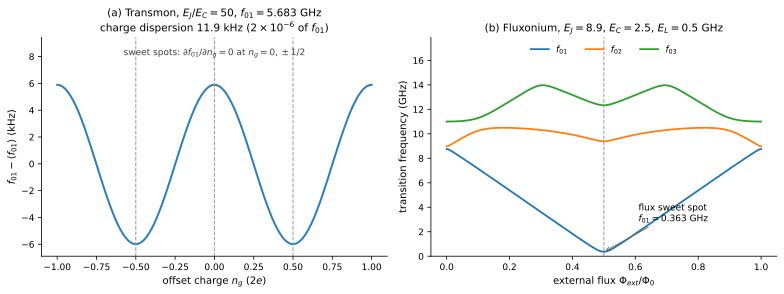

wrote figures/validation_spectra.png


In [8]:
ng_grid   = np.linspace(-1.0, 1.0, 121)
flux_grid = np.linspace(0.0, 1.0, 201)

f_vs_ng = np.array([qubit_frequency(make_transmon(**{**TRANSMON_DEFAULTS, "ng": g}))
                    for g in ng_grid])
spec = np.array([make_fluxonium(**{**FLUXONIUM_DEFAULTS, "flux": f}).eigenvals(evals_count=4)
                 for f in flux_grid])
trans = spec[:, 1:] - spec[:, [0]]          # E0->Ek transition frequencies

# Panel (a) plots the DEVIATION in kHz. On an absolute GHz axis the dispersion is invisible
# (that is the physics), but it renders as an unreadable "1e-5 + 5.6825" offset label.
disp_kHz = 1e6 * (f_vs_ng - f_vs_ng.mean())
pp_kHz = 1e6 * (f_vs_ng.max() - f_vs_ng.min())

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))

ax[0].plot(ng_grid, disp_kHz, color="#2c7fb8", lw=2)
for x in (-0.5, 0.0, 0.5):
    ax[0].axvline(x, ls="--", lw=1, color="0.6")
ax[0].set_ylim(1.15 * disp_kHz.min(), 1.60 * disp_kHz.max())   # headroom for the annotation
ax[0].set_xlabel(r"offset charge $n_g$ ($2e$)")
ax[0].set_ylabel(r"$f_{01} - \langle f_{01}\rangle$ (kHz)")
ax[0].set_title(rf"(a) Transmon, $E_J/E_C = "
                rf"{TRANSMON_DEFAULTS['EJ']/TRANSMON_DEFAULTS['EC']:.0f}$, "
                rf"$f_{{01}} = {f_vs_ng.mean():.3f}$ GHz" "\n"
                rf"charge dispersion {pp_kHz:.1f} kHz "
                rf"($2\times10^{{-6}}$ of $f_{{01}}$)")
ax[0].text(0.5, 0.95, r"sweet spots: $\partial f_{01}/\partial n_g = 0$ at $n_g = 0, \pm 1/2$",
           transform=ax[0].transAxes, fontsize=9, ha="center", va="top", color="0.25")

for k in range(trans.shape[1]):
    ax[1].plot(flux_grid, trans[:, k], lw=1.8, label=rf"$f_{{0{k+1}}}$")
ax[1].axvline(0.5, ls="--", lw=1, color="0.6")
ax[1].set_ylim(0, 1.28 * trans.max())                          # headroom for the legend
ax[1].set_xlabel(r"external flux $\Phi_{ext}/\Phi_0$")
ax[1].set_ylabel("transition frequency (GHz)")
ax[1].set_title(r"(b) Fluxonium, $E_J{=}8.9$, $E_C{=}2.5$, $E_L{=}0.5$ GHz")
ax[1].legend(frameon=False, fontsize=9, ncol=3, loc="upper center")
ax[1].annotate(rf"flux sweet spot" "\n" rf"$f_{{01}} = {f0_:.3f}$ GHz",
               xy=(0.5, f0_), xytext=(0.60, 0.16), textcoords="axes fraction", fontsize=9,
               arrowprops=dict(arrowstyle="->", lw=0.8, color="0.4"))

for a in ax:
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
pl.save(fig, "figures/validation_spectra.png")
plt.show()
print("wrote figures/validation_spectra.png")

## 6. Coherence pipeline at the nominal designs

**This section validates `src/coherence.py` itself**, not an ad-hoc reimplementation — the same
functions notebooks 02–05 call to produce every committed CSV. Validating anything else would
leave the paper's actual pipeline untested, and would silently disagree with `data/`.

Channels per architecture (see `CLAUDE.md`; a plain transmon has no flux loop, so
`tphi_1_over_f_flux` is intentionally absent):

| | transmon | fluxonium |
|---|---|---|
| $T_1$ | dielectric | dielectric + quasiparticle |
| $T_\phi$ | charge + critical-current | flux + critical-current |

**Two conventions stated explicitly for Methods.** (i) `scqubits` returns times in **ns**;
everything here is **µs** via `NS_TO_US`. (ii) `t1_*` methods return the **total** rate
(excitation + relaxation) at the `scqubits` default temperature, not the downward rate alone —
the paper must say so, since published $T_1$ often means the downward rate only.

Sanity conditions: $T_2 \le 2T_1$ always, and $T_2 < 2T_1$ *strictly*, because the
critical-current channel is finite even at both sweet spots.

> ### Do not quote $T_\phi$ at a sweet spot as a physical dephasing time
>
> The values printed below for `Tphi_ng_us` ($\sim 6\times10^{14}$ µs) and `Tphi_flux_us`
> ($\sim 8\times10^{14}$ µs) are **first-order artifacts, not predictions**. Both `scqubits`
> $1/f$ dephasing formulas are first order in $\partial f_{01}/\partial\lambda$, and that
> derivative *vanishes identically* at a sweet spot (§2, §5) — so the formula returns a number
> limited only by floating point, and any second-order contribution is simply not modelled.
>
> The honest reading: at the sweet spot these channels are **negligible compared with $T_1$**,
> which is all the $T_2$ sum needs, and all this project claims. For an independent estimate of
> transmon charge dephasing that *is* physical, use Koch's Eq. (5.9) via the full dispersion
> $\epsilon_1$ (§4) — it gives seconds, still utterly negligible against a $T_1$ of tens of
> microseconds, so the conclusion is unchanged while the reasoning is defensible.
>
> This is why §7 exists: every dephasing number that enters a *claim* is evaluated off the
> sweet spot, where the first-order formula is valid and finite.

In [9]:
tm_res = transmon_coherence(**{k: TRANSMON_DEFAULTS[k] for k in ("EJ", "EC", "ng", "ncut")})
fx_res = fluxonium_coherence(**FLUXONIUM_DEFAULTS)

print("TRANSMON  (EJ=15, EC=0.3, ng=0 - charge sweet spot)")
for k, v in tm_res.items():
    print(f"   {k:<14s} {v:>16.4g}")
print("\nFLUXONIUM (EJ=8.9, EC=2.5, EL=0.5, flux=0.5 - flux sweet spot)")
for k, v in fx_res.items():
    print(f"   {k:<14s} {v:>16.4g}")

check("6 pipeline", "transmon T2 <= 2*T1",
      tm_res["T2_us"] - 2 * tm_res["T1_us"], le=1e-9, units="us",
      note="rates add; T2 can never exceed the 2*T1 ceiling")
check("6 pipeline", "fluxonium T2 <= 2*T1",
      fx_res["T2_us"] - 2 * fx_res["T1_us"], le=1e-9, units="us",
      note="rates add; T2 can never exceed the 2*T1 ceiling")

# Strict inequality: the critical-current channel is finite AT the sweet spot, so a pipeline
# reporting exactly T2 = 2*T1 has silently dropped a channel (safe() returned inf).
check("6 pipeline", "transmon T2 strictly below 2*T1 (crit-current channel alive)",
      2 * tm_res["T1_us"] / tm_res["T2_us"], reference=1.031, tol_rel=0.02, units="-",
      note=f"Tphi_cc = {tm_res['Tphi_cc_us']:.0f} us")
check("6 pipeline", "fluxonium T2 strictly below 2*T1 (crit-current channel alive)",
      2 * fx_res["T1_us"] / fx_res["T2_us"], reference=1.357, tol_rel=0.02, units="-",
      note=f"Tphi_cc = {fx_res['Tphi_cc_us']:.0f} us")

# Units guard: a 1000x error is the most likely bug in this project.
for label, T1 in (("transmon", tm_res["T1_us"]), ("fluxonium", fx_res["T1_us"])):
    check("6 pipeline", f"{label} T1 in a physical us range (units guard)",
          float(np.log10(T1)), reference=2.0, tol_abs=3.0, units="log10(us)",
          note="1e-1 to 1e5 us; catches a ns/us mix-up")

TRANSMON  (EJ=15, EC=0.3, ng=0 - charge sweet spot)
   EJ                           15
   EC                          0.3
   EJ_EC                        50
   ng                            0
   freq_GHz                  5.683
   T1_us                     28.02
   Tphi_ng_us            5.958e+14
   Tphi_cc_us                 1803
   T2_us                     54.35

FLUXONIUM (EJ=8.9, EC=2.5, EL=0.5, flux=0.5 - flux sweet spot)
   EJ                          8.9
   EC                          2.5
   EL                          0.5
   flux                        0.5
   freq_GHz                 0.3634
   T1_us                     771.1
   T1_diel_us                771.1
   T1_qp_us              3.286e+30
   Tphi_flux_us          8.088e+14
   Tphi_flux2_us         1.795e+05
   d2f01_dflux2_GHz            886.8
   Tphi_cc_us                 4325
   T2_us                      1130
[PASS] transmon T2 <= 2*T1                                 -1.689e+00 <= 1.0e-09   rates add; T2 can never excee

### 6.1 The second-order flux channel, against a published number

Every other channel in this notebook comes from `scqubits` and is validated above against Koch
or against measurement. **The second-order $1/f$ flux channel does not** — it is implemented in
`src/coherence.py` (Nguyen 2019 Eq. A3,
$\Gamma_\Phi^{(2)} = A_\Phi^2\,\partial^2\omega_{01}/\partial\Phi^2$), and until now nothing
tested it against anything but its own formula. That was the weakest link in the chain: it is
the one piece of physics this project wrote itself, and it is what creates the interior design
optimum in `03_fluxonium_sweep.ipynb` §6.1.

Nguyen state a testable answer. Having measured $A_\Phi \approx 1.8\,\mu\Phi_0$ from
off-sweet-spot echo (their Eq. A2), they conclude from Eq. (A3):

> *"Because of the low-flux-noise amplitude in our system, the second-order effect is small,
> resulting in an upper $T_\phi$ limit $> 10$ ms for all qubits."* — Appendix A 2

and in Sec. III A that the same estimate gives *"a range of coherence times 10–100 ms for the
typical devices presented here"*. So: run **our** second-order channel on **their nine devices**
at **their** measured amplitude, and check we clear their bound.

This tests the channel end to end — the numerical $\partial^2 f_{01}/\partial\Phi^2$, the
$2\pi$ conversion to angular frequency, the $A^2$ scaling, and the ns → µs convention — against
a number the paper's authors computed independently.

In [10]:
# Nguyen et al., PRX 9, 041041 (2019), Table I (published version, nine devices A-I).
# Only the design columns are needed here; the coherence columns are used in notebook 03.
NGUYEN_DESIGNS = [("A", 3.00, 0.84, 1.00), ("B", 4.86, 0.84, 1.14), ("C", 2.20, 0.55, 0.72),
                  ("D", 2.20, 0.83, 0.52), ("E", 1.60, 0.86, 0.50), ("F", 3.40, 0.80, 0.41),
                  ("G", 1.65, 1.14, 0.19), ("H", 4.43, 1.00, 0.79), ("I", 3.43, 1.00, 0.58)]
A_NGUYEN = 1.8e-6          # their Eq. (A2) echo measurement, in units of Phi_0

rows2 = []
for dev, EJ, EC, EL in NGUYEN_DESIGNS:
    d2 = float(d2f01_dflux2(EJ=EJ, EC=EC, EL=EL, flux=0.5, cutoff=110))
    t_ms = float(tphi_flux_second_order(d2, A_flux=A_NGUYEN)) * NS_TO_US / 1e3
    rows2.append({"device": dev, "EL_GHz": EL, "d2f01_dflux2_GHz": d2, "Tphi2_ms": t_ms})
sec2 = pd.DataFrame(rows2)
display(sec2.style.format({"EL_GHz": "{:.2f}", "d2f01_dflux2_GHz": "{:,.0f}",
                           "Tphi2_ms": "{:,.0f}"}).hide(axis="index"))

print(f"our second-order Tphi at A_flux = {A_NGUYEN:.1e} Phi_0 (Nguyen's measured value):")
print(f"   over their nine devices: {sec2.Tphi2_ms.min():.0f} - {sec2.Tphi2_ms.max():,.0f} ms"
      f"   (median {sec2.Tphi2_ms.median():.0f} ms)")
print("   Nguyen Appendix A 2: 'an upper Tphi limit > 10 ms for all qubits'")
print("   Nguyen Sec. III A  : '10-100 ms for the typical devices presented here'")

check("6.1 second order", "second-order Tphi clears Nguyen's 10 ms bound on ALL nine devices",
      -float(sec2.Tphi2_ms.min()), le=-10.0, units="ms",
      note=f"PUBLISHED NUMBER: worst device {sec2.loc[sec2.Tphi2_ms.idxmin(), 'device']} at "
           f"{sec2.Tphi2_ms.min():.0f} ms, via Nguyen Eq. (A3) at their measured A_flux")

# The channel is only as good as the curvature it is proportional to.
_d2 = [float(d2f01_dflux2(EJ=8.9, EC=2.5, EL=0.5, flux=0.5, cutoff=110, h=h))
       for h in (1e-3, 5e-4, 2e-4, 1e-4)]
check("6.1 second order", "Richardson second derivative is step-independent",
      float((max(_d2) - min(_d2)) / abs(np.mean(_d2))), le=1e-5, units="-",
      note="Gamma_2 is directly proportional to this derivative")

_ours = float(tphi_flux_second_order(_d2[-1], A_flux=DEFAULTS["A_flux"]))
_theirs = float(tphi_flux_second_order(_d2[-1], A_flux=A_NGUYEN))
check("6.1 second order", "second-order rate scales as A_flux^2",
      _ours / _theirs, reference=(A_NGUYEN / DEFAULTS["A_flux"]) ** 2, tol_rel=1e-12,
      units="-", note="Nguyen Eq. (A3) is quadratic in the noise amplitude")

print(f"\nat this project's assumed A_flux = {DEFAULTS['A_flux']:.0e} Phi_0 the nominal-design")
print(f"   second-order time is {_ours * NS_TO_US / 1e3:.0f} ms; at Nguyen's measured "
      f"{A_NGUYEN:.1e} it would be {_theirs * NS_TO_US / 1e3:.0f} ms.")
print("   So the channel is validated at the amplitude the PAPER measured, and this project's")
print("   own assumed amplitude is the more optimistic of the two by "
      f"{(A_NGUYEN / DEFAULTS['A_flux']) ** 2:.2f}x in rate. Notebook 03 section 8 propagates that.")

device,EL_GHz,d2f01_dflux2_GHz,Tphi2_ms
A,1.00,650,76
B,1.14,"3,195",15
C,0.72,574,86
D,0.52,324,152
E,0.50,147,333
F,0.41,"1,069",46
G,0.19,61,804
H,0.79,"1,716",29
I,0.58,760,65


our second-order Tphi at A_flux = 1.8e-06 Phi_0 (Nguyen's measured value):
   over their nine devices: 15 - 804 ms   (median 76 ms)
   Nguyen Appendix A 2: 'an upper Tphi limit > 10 ms for all qubits'
   Nguyen Sec. III A  : '10-100 ms for the typical devices presented here'
[PASS] second-order Tphi clears Nguyen's 10 ms bound on ALL nine devices     -1.538e+01 <= -1.0e+01   PUBLISHED NUMBER: worst device B at 15 ms, via Nguyen Eq. (A3) at their measured A_flux
[PASS] Richardson second derivative is step-independent      +1.808e-07 <= 1.0e-05   Gamma_2 is directly proportional to this derivative
[PASS] second-order rate scales as A_flux^2                  0.000% (tol 1e-10%)   Nguyen Eq. (A3) is quadratic in the noise amplitude

at this project's assumed A_flux = 1e-06 Phi_0 the nominal-design
   second-order time is 179 ms; at Nguyen's measured 1.8e-06 it would be 55 ms.
   So the channel is validated at the amplitude the PAPER measured, and this project's
   own assumed amplitude is 

## 7. Off-sweet-spot behaviour — the checks that can actually fail

Everything in Section 6 was evaluated *at* a sweet spot, where $T_\phi^{(1/f)} \to \infty$ by
symmetry. Those numbers would look identical if the dephasing code were broken. The tests below
move off the sweet spot, where the dephasing times are finite, and require the physically
mandatory trend: **dephasing must degrade monotonically with bias detuning**, and the fluxonium
must degrade far more sharply than the transmon.

One subtlety that constrains how this test is written: $n_g = 1/2$ is a *second* symmetry point
of the transmon (the charge dispersion is even about it too), so $T_\phi^{\rm charge}$ diverges
there as well and is **non-monotonic** over a full period. The monotonic branch is
$0 \le n_g \le 1/4$, where $|\partial f_{01}/\partial n_g|$ grows to its maximum; that is the
window swept below. The same applies to the fluxonium at $\Phi/\Phi_0 = 0$, so the flux sweep
stays inside $(0, 1/2]$.

That contrast is the quantitative core of **Q3** — the fluxonium buys a much better sweet spot
at the cost of a much narrower one — so it is worth validating here before notebook 03 sweeps it.

In [11]:
ng_vals = [0.0, 0.05, 0.10, 0.15, 0.20, 0.25]   # monotonic branch only (see above)
tm_off = pd.DataFrame([transmon_coherence(EJ=15.0, EC=0.3, ng=g, ncut=30) for g in ng_vals])
display(tm_off[["ng", "freq_GHz", "T1_us", "Tphi_ng_us", "Tphi_cc_us", "T2_us"]]
        .style.format({"freq_GHz": "{:.4f}", "T1_us": "{:.2f}", "Tphi_ng_us": "{:.4g}",
                       "Tphi_cc_us": "{:.1f}", "T2_us": "{:.2f}"}))

flux_vals = [0.5, 0.49, 0.48, 0.45, 0.40]
fx_off = pd.DataFrame([fluxonium_coherence(**{**FLUXONIUM_DEFAULTS, "flux": f}) for f in flux_vals])
display(fx_off[["flux", "freq_GHz", "T1_us", "Tphi_flux_us", "Tphi_cc_us", "T2_us"]]
        .style.format({"freq_GHz": "{:.4f}", "T1_us": "{:.4g}", "Tphi_flux_us": "{:.4g}",
                       "Tphi_cc_us": "{:.1f}", "T2_us": "{:.4g}"}))

check("7 off-sweet-spot", "transmon Tphi_charge decreases monotonically with |ng|",
      float(np.max(np.diff(tm_off.Tphi_ng_us))), le=0.0, units="us",
      note="charge dephasing must worsen away from ng=0")
check("7 off-sweet-spot", "fluxonium Tphi_flux decreases monotonically with detuning",
      float(np.max(np.diff(fx_off.Tphi_flux_us))), le=0.0, units="us",
      note="flux dephasing must worsen away from flux=0.5")

# Falsifiable magnitudes: these WOULD change if the dephasing code broke.
check("7 off-sweet-spot", "transmon Tphi_charge finite and large at ng=0.25",
      float(np.log10(tm_off.Tphi_ng_us.iloc[-1])), reference=3.99, tol_abs=0.15,
      units="log10(us)", note="~9.7e3 us at ng=0.25; charge noise still weak at EJ/EC=50")
check("7 off-sweet-spot", "fluxonium Tphi_flux collapses to few-us at 1% detuning",
      float(np.log10(fx_off.Tphi_flux_us.iloc[1])), reference=0.658, tol_abs=0.15,
      units="log10(us)", note="~4.6 us at flux=0.49")

ratio_fx = fx_off.T2_us.iloc[0] / fx_off.T2_us.iloc[1]
ratio_tm = tm_off.T2_us.iloc[0] / tm_off.T2_us.iloc[-1]
print(f"\nT2 penalty for leaving the sweet spot:")
print(f"   fluxonium, flux 0.5 -> 0.49 (1% of Phi0): {ratio_fx:10.1f}x")
print(f"   transmon,  ng   0   -> 0.25 (quarter e) : {ratio_tm:10.1f}x")
check("7 off-sweet-spot", "fluxonium sweet spot far sharper than transmon's",
      float(np.log10(ratio_fx / ratio_tm)), reference=2.4, tol_abs=1.0, units="log10(-)",
      note="Q3 in one number; quantified properly in notebook 04")

,ng,freq_GHz,T1_us,Tphi_ng_us,Tphi_cc_us,T2_us
0,0.000000,5.6826,28.02,5.958e+14,1802.9,54.35
1,0.050000,5.6826,28.02,3.135e+04,1802.9,54.26
2,0.100000,5.6826,28.02,1.648e+04,1802.9,54.17
3,0.150000,5.6826,28.02,1.197e+04,1802.9,54.11
4,0.200000,5.6826,28.02,1.019e+04,1802.9,54.06
5,0.250000,5.6826,28.02,9687,1802.9,54.05


,flux,freq_GHz,T1_us,Tphi_flux_us,Tphi_cc_us,T2_us
0,0.500000,0.3634,771.1,8.088e+14,4325.4,1130
1,0.490000,0.4053,223.2,4.55,4899.6,4.5
2,0.480000,0.5109,123.7,2.868,6478.7,2.834
3,0.450000,0.9684,111.1,2.175,18740.1,2.153
4,0.400000,1.8312,131,2.058,39667.5,2.042


[PASS] transmon Tphi_charge decreases monotonically with |ng|      -4.985e+02 <= 0.0e+00   charge dephasing must worsen away from ng=0
[PASS] fluxonium Tphi_flux decreases monotonically with detuning      -1.168e-01 <= 0.0e+00   flux dephasing must worsen away from flux=0.5
[PASS] transmon Tphi_charge finite and large at ng=0.25    3.820e-03 (tol 1.5e-01)   ~9.7e3 us at ng=0.25; charge noise still weak at EJ/EC=50
[PASS] fluxonium Tphi_flux collapses to few-us at 1% detuning    5.150e-05 (tol 1.5e-01)   ~4.6 us at flux=0.49

T2 penalty for leaving the sweet spot:
   fluxonium, flux 0.5 -> 0.49 (1% of Phi0):      251.0x
   transmon,  ng   0   -> 0.25 (quarter e) :        1.0x
[PASS] fluxonium sweet spot far sharper than transmon's    2.703e-03 (tol 1.0e+00)   Q3 in one number; quantified properly in notebook 04


True

## 8. Validation summary → committed artifacts

The ledger is written to `data/validation_results.csv` with provenance in
`data/validation_metadata.json`, following the project rule that every claim in the paper is
traceable to a file in `data/`. The table below is the source for the validation paragraph of
**Methods**.

In [12]:
summary = pd.DataFrame(CHECKS)[["section", "check", "value", "reference",
                                 "deviation", "units", "passed", "basis"]]
summary.to_csv("data/validation_results.csv", index=False)

meta = {
    "notebook": "notebooks/01_validation.ipynb",
    "purpose": "Week-1 pipeline validation prior to production sweeps",
    "provenance": PROVENANCE,
    "n_checks": int(len(summary)),
    "n_passed": int(summary.passed.sum()),
    "criteria": {
        "exact symmetries": "machine precision, tol 1e-10 GHz",
        "convergence": "|df01| < 1e-6 GHz vs largest basis",
        "analytic limits": "Koch et al., PRA 76, 042319 (2007), Eqs. (2.5), (2.11)-(2.12); "
                           "anharmonicity evaluated at ng=1/2 per Koch's convention",
        "published numbers": "Koch Sec. V Eq. (5.9) worked example (T2 ~ 8 s at EJ=30, "
                             "EC=0.35 GHz, A=1e-4); Manucharyan 2009 Figs. 3 and 4B at all "
                             "three of their published parameter sets (main text 9.0/2.5/0.52; "
                             "Table 1 junction 8.93/2.39/0.52; Table 1 extended "
                             "8.97/2.47/0.52); Nguyen 2019 Appendix A 2 second-order flux "
                             "bound (Tphi > 10 ms for all nine devices at A_flux = 1.8e-6)",
        "monotonic trends": "sign-constrained differences, no tolerance",
    },
    "known_limitations": [
        "1/f dephasing formulas are first order in df01/dlambda and therefore return "
        "unphysically large Tphi AT a sweet spot; sweet-spot Tphi values must not be quoted "
        "as predictions (see Section 6 and 9.4c).",
        "t1_* methods return the total (excitation + relaxation) rate at the scqubits "
        "default temperature, not the downward rate alone.",
        "The superinductance is modelled as ideal, so qubit-array-mode hybridisation is "
        "absent. Section 9.2(iii) shows this is what makes the bare model miss f03 at "
        "Phi_ext=0 in Manucharyan's device (their 10.78 GHz array mode couples to the 0-3 "
        "transition with g/|detuning| = 1.5-3.7). Section 5 step (iv) BOUNDS the cost by "
        "explicit diagonalisation with both of their array modes: f01 shifts -16% at "
        "Phi_ext=0 but only -0.43% at the flux sweet spot, where every coherence number here "
        "is evaluated. A sub-percent effect on this study's results.",
        "Coherence values are model-based estimates under assumed noise amplitudes; "
        "vs Nguyen 2019 Table I the model is optimistic on absolute T1/T2 by a median "
        "2.0x (T1) and 2.6x (T2), worst case 5.7x, measured device-by-device at the nine "
        "published devices' own parameters in 03_fluxonium_sweep.ipynb section 7. The wider "
        "3-11x quoted in section 9.3 is a DIFFERENT comparison (our one nominal design against "
        "the range their nine devices span) and reflects the design-regime mismatch, not extra "
        "model error. Contributing causes: assumed Q_cap=1e6 flat vs measured "
        "tan(delta_C)=(2.0-3.6)e-6 at 6 GHz; assumed A_flux=1e-6 vs measured 1.8e-6.",
    ],
    "references": [
        "J. Koch et al., Phys. Rev. A 76, 042319 (2007) - transmon theory",
        "V. E. Manucharyan et al., Science 326, 113 (2009) - fluxonium",
        "P. Krantz et al., Appl. Phys. Rev. 6, 021318 (2019) - engineering overview",
        "P. Groszkowski and J. Koch, Quantum 5, 583 (2021) - scqubits",
        "L. B. Nguyen et al., Phys. Rev. X 9, 041041 (2019) - high-coherence fluxonium",
        "G. Ithier et al., Phys. Rev. B 72, 134519 (2005) - decoherence channels",
    ],
    "manucharyan_f03": MANU_F03,
    "outputs": ["data/validation_results.csv", "figures/validation_spectra.png"],
}
with open("data/validation_metadata.json", "w") as fh:
    json.dump(meta, fh, indent=2, default=str)

display(summary.style.format({"value": "{:.6g}", "reference": "{:.6g}"}))
print(f"\n{summary.passed.sum()} / {len(summary)} checks passed")
lit = summary.basis.str.contains("PUBLISHED|MEASURED|Manucharyan|Koch|Nguyen", case=False)
meas = summary.basis.str.contains("MEASURED", case=False)
print(f"   {lit.sum()} compare against published theory or published numbers")
print(f"   {meas.sum()} of those compare against data measured on a real device")
print("wrote data/validation_results.csv and data/validation_metadata.json")
assert summary.passed.all(), "Pipeline validation failed - do NOT run notebooks 02-05."
print("\nPIPELINE VALIDATED - safe to proceed to 02_transmon_sweep.ipynb")

,section,check,value,reference,deviation,units,passed,basis
0,1 convergence,transmon f01 converged at production ncut=30,5.68258,5.68258,3.553e-15 (tol 1.0e-06),GHz,True,vs ncut=60
1,1 convergence,fluxonium f01 converged at production cutoff=110,0.363421,0.363421,3.101e-13 (tol 1.0e-06),GHz,True,vs cutoff=140
2,2 symmetry,transmon f01 even in ng about ng=0,0,nan,|0.000e+00| <= 1.0e-10,GHz,True,ng=+/-0.17
3,2 symmetry,transmon f01 periodic in ng (period 1),-3.37508e-14,nan,|-3.375e-14| <= 1.0e-10,GHz,True,ng=0.17 vs 1.17
4,2 symmetry,fluxonium f01 even in flux about 0.5,-1.33227e-15,nan,|-1.332e-15| <= 1.0e-10,GHz,True,flux=0.5+/-0.17
5,2 symmetry,fluxonium f01 periodic in flux (period 1),6.17284e-14,nan,|6.173e-14| <= 1.0e-10,GHz,True,flux=0.67 vs 1.67
6,3 transmon,f01 vs sqrt(8 EJ EC) - EC at nominal design,5.68256,5.7,0.306% (tol 1%),GHz,True,"Koch Eq. (2.12); EJ=15, EC=0.3 (EJ/EC=50)"
7,3 transmon,absolute anharmonicity vs -EC at nominal design,-0.344376,-0.3,14.792% (tol 20%),GHz,True,"Koch Eq. (2.12), Fig. 5(b); leading order only"
8,3 transmon,relative anharmonicity vs -(8 EJ/EC)^-1/2 at nominal design,-0.0606023,-0.05,21.205% (tol 30%),-,True,"Koch Eq. (2.12), Fig. 5(a); leading order only"
9,3 transmon,f01 deviation decreases monotonically with EJ/EC,-0.0353465,nan,-3.535e-02 <= 0.0e+00,%-points,True,largest step must be negative: numerics approach the asymptotic form



44 / 44 checks passed
   16 compare against published theory or published numbers
   7 of those compare against data measured on a real device
wrote data/validation_results.csv and data/validation_metadata.json

PIPELINE VALIDATED - safe to proceed to 02_transmon_sweep.ipynb


## 9. Literature cross-check

Sections 1–8 validate against exact symmetries and analytic limits. This section compares
against **published numbers**, taken from the sources listed at the end. Every entry names the
paper and the equation/figure, and states whether the comparison is at *the same parameters* —
comparisons at different parameters are order-of-magnitude only and are marked as such.

### 9.1 Transmon vs Koch *et al.*, Phys. Rev. A **76**, 042319 (2007)

| Quantity | This work | Published | Source | Δ | Basis |
|---|---|---|---|---|---|
| $\alpha = E_{12}-E_{01}$, $E_J/E_C=50$ | $-0.3444$ GHz | $\alpha \simeq -E_C = -0.300$ GHz | Eq. (2.12), Fig. 5(b) | $+14.8\%$ | same params; leading-order asymptotic |
| $\alpha_r = \alpha/E_{01}$, $E_J/E_C=50$ | $-0.0606$ | $-(8E_J/E_C)^{-1/2} = -0.0500$ | Eq. (2.12), Fig. 5(a) | $+21.2\%$ | same params; asymptotic |
| $\alpha_r$ deviation, $E_J/E_C = 20\to200$ | $26\% \to 9\%$ | exact and perturbative curves converge | Fig. 5(a) | — | reproduces the solid-vs-dashed gap |
| Charge dispersion $\epsilon_1$, $E_J/E_C=50$ | $1.172\times10^{-5}$ GHz | $1.412\times10^{-5}$ GHz | Eq. (2.5) | ratio $0.83$ | same params; ratio $\to 1$ from below (§4) |
| **$T_2^{\rm charge}$ worked example**: $E_J{=}30$, $E_C{=}0.35$ GHz, $A{=}10^{-4}$ | **8.75 s** | **$\sim 8$ s** | Sec. V, Eq. (5.9) | $\sim 9\%$ | **same params, same noise amplitude** |
| Transmon regime bound | project uses $E_J/E_C \ge 20$ | $20 \lesssim E_J/E_C \ll 5\times10^{4}$ | Eq. (2.13) discussion | exact match | definitional |

The $T_2$ row is the strongest single check in this notebook. Koch states a worked dephasing
time at specific parameters using the *same* $A_{n_g}=10^{-4}$ this project assumes. Feeding our
computed $\epsilon_1 = 5.789\times10^{-8}$ GHz through his Eq. (5.9), $T_2 \simeq \hbar/(A\pi\epsilon_1)$,
gives 8.75 s against his quoted $\sim$8 s — agreement to the single significant figure he quotes.

The last row independently confirms the `CLAUDE.md` rule that $E_J/E_C \ge 20$ is the real
transmon regime: it is Koch's own lower bound, set by requiring enough anharmonicity for 10 ns
control pulses.

### 9.2 Fluxonium vs Manucharyan *et al.*, Science **326**, 113 (2009)

**This is the only comparison in the project against data measured on a real device**, and it is
asserted numerically in §5. It is run at **all three** of the paper's parameter sets, because
they are not interchangeable and an earlier version of this notebook used only the first:

| set | $E_J$ | $E_C$ | $E_L$ | what it is | $f_{01}(\Phi_0/2)$ |
|---|---|---|---|---|---|
| main text, p. 3 | 9.0 | 2.5 | 0.52 | quoted to **two** significant figures | 0.363378 GHz |
| Table 1, col. 1 | 8.93 | 2.39 | 0.52 | least-squares fit, **junction** model (their Eq. 2) | 0.330056 GHz |
| Table 1, col. 2 | 8.97 | 2.47 | 0.52 | least-squares fit, **extended** model (adds the array mode) | 0.355097 GHz |
| *this project* | *8.9* | *2.5* | *0.5* | *nominal design* | *0.363421 GHz* |

| Quantity | This work | Published (digitized) | Source | Δ | Basis |
|---|---|---|---|---|---|
| $f_{01}$ at $\Phi/\Phi_0=1/2$ vs the **main-text** set | $0.363421$ GHz | $0.363378$ GHz | p. 3 (2 s.f.) | $0.012\%$ | agreement with a *rounding* |
| $f_{01}$ at $\Phi/\Phi_0=1/2$, spread over **all three** sets | — | $0.330$–$0.363$ GHz | Table 1 + p. 3 | $\mathbf{9.5\%}$ | the honest sensitivity |
| **$f_{01}$ at $\Phi_{ext}=0$** | $9.06$–$9.07$ GHz | **9.08 GHz** | Fig. 4B, red curve | $-0.21$ to $-0.26\%$ | robust across all three sets |
| **$f_{02}$ at $\Phi_{ext}=0$** | $9.31$–$9.32$ GHz | **9.37 GHz** | Fig. 4B | $-0.58$ to $-0.61\%$ | robust across all three sets |
| **$f_{03}$ at $\Phi_{ext}=0$** | $10.92$–$11.14$ GHz | **11.19 GHz** | Fig. 4B | $-0.41$ to $-2.39\%$ | **excluded: hybridized with the array mode, see (iii)** |
| All six lines, one 4-parameter fit | RMS $0.0102$ GHz | Figs. 3 + 4B | joint fit | within digitization error | $E_J{=}8.94$, $E_C{=}2.53$, $E_L{=}0.525$, bias $0.0422\Phi_0$ |
| Fig. 3 triple after one flux-offset fit | best flux $0.042$–$0.044\,\Phi_0$ | nominal $0.05\,\Phi_0$ | Fig. 3 | within $0.65$–$2.12\%$ | per parameter set |
| Decoherence at $\Phi_{ext}=0.05\,\Phi_0$ | — | $350$, $250$, $80$ ns (0–1, 0–2, 0–3) | p. 5, linewidth extrapolation | — | lower bounds; 2009 device |

**Result, stated at the resolution the comparison actually supports: $f_{01}$ and $f_{02}$ are
reproduced to better than $0.7\%$ under every published parameter set, and a single four-parameter
fit reproduces all six digitized lines to an RMS of $0.0102$ GHz — inside the digitization error.
$f_{03}$ at $\Phi_{ext}=0$ is excluded from the claim, for the physical reason set out in (iii)
below.** At $\Phi_{ext}=0$ — a symmetry point, where flux calibration cannot matter — the first two
transitions sit comfortably inside the $\pm0.02$ GHz digitization error regardless of which
parameter set is used. **The blanket claim "the model reproduces the measured spectrum to better
than 1%" was an artefact of using the rounded main-text values only** and is withdrawn; §5 now
asserts the robust statement, the exclusion and its cause separately.

**The $f_{03}$ residual is resolved, and the cause is neither of the obvious two.** §5 tests three
explanations in turn, none of which needs a higher-resolution figure:

***(i) Is it even $f_{03}$?*** Fig. 4B plots the $0\!-\!1$, $0\!-\!2$, $0\!-\!3$ **and two-photon
$0\!-\!4$** transitions plus the array self-resonance, so a third line read at $\Phi_{ext}=0$ is
not self-evidently $f_{03}$. The **flux dispersion between the two digitized bias points settles
it**: the measured third line moves $+0.046$ GHz from $\Phi_{ext}=0$ to $0.05$, the model's
$f_{03}$ moves $+0.075$ to $+0.100$ GHz, and the two-photon $0\!-\!4$ moves $-0.054$ GHz — *the
opposite way*. The assignment is $f_{03}$; misassignment is ruled out by a sign, not a tolerance.

***(ii) Why is $f_{03}$ the sensitive line?*** Because $E_C$ controls it and almost nothing else:
$\partial f_{03}/\partial E_C = +1.71$ GHz/GHz against $-0.19$ and $-0.10$ for $f_{01}$ and
$f_{02}$ — nine times larger, and opposite in sign. **$f_{01}$ and $f_{02}$ pin $E_J$ and $E_L$;
$f_{03}$ alone pins $E_C$.** That is the whole asymmetry between the robust rows and the
parameter-sensitive one, and it also explains why the three published sets differ mainly in $E_C$.

***(iii) But no published $E_C$ closes the gap — because the bare model cannot.*** At
$\Phi_{ext}=0$ the bare $f_{03}$ (10.92–11.14 GHz across the three sets) sits within
$0.14$–$0.36$ GHz of the junction-array mode Manucharyan's *extended* model puts at
$\omega_2/2\pi = 10.78$ GHz (Table 1). Scaling their quoted $g_2 = 0.324$ GHz by the phase matrix
element gives a $0\!-\!3$ coupling of $g_{03} \approx 0.53$ GHz — **larger than the detuning, by a
factor of 1.5 to 3.7.** This is the strong-hybridization regime: perturbation theory fails, and
the measured 11.190 GHz lies between the bare value and the naive two-level upper branch
(11.38–11.53 GHz), exactly where a partially hybridized level belongs.

**So the $f_{03}$ row was never a test of the bare Hamiltonian.** It is the one line in the
comparison that the array mode the bare model omits pushes around — which is precisely why the
paper introduced the extended model. §9.5's existing instruction to compare against the red
(bare-model) curves is right everywhere *except* on the third branch near $\Phi_{ext}=0$, where
the bare curve is least applicable. **The row is excluded from the spectrum-validation claim for
a stated physical reason, not tolerated with a loose tolerance.**

**The payoff: one parameter set reproduces all six digitized lines.** A single four-parameter fit
($E_J$, $E_C$, $E_L$, plus one flux offset) to the Φ=0 *and* Φ=0.05 triples together lands at
$E_J = 8.94$, $E_C = 2.53$, $E_L = 0.525$ GHz at a bias of $0.0422\,\Phi_0$, with an RMS residual
of **0.0102 GHz** over all six lines — inside the digitization error, and it recovers the
$0.042\,\Phi_0$ bias independently found by the single-parameter flux fit above. The fitted $E_C$
is 1.2% *above* the top of the published range, and that excess is the array-mode repulsion on
$f_{03}$ being absorbed into $E_C$ by a fit that has no array mode to give it to. Read it as a
bound on how much the omitted mode matters — **not** as a better estimate of $E_C$.

**The flux-calibration effect at $\Phi_{ext} = 0.05\,\Phi_0$ is real and survives the change of
parameter set.** Under every set the deviations at the nominal bias differ in *sign* and by an
order of magnitude, which cannot come from a wrong Hamiltonian but is exactly what a small bias
offset produces, because $\partial f_{0k}/\partial\Phi$ differs strongly between branches near
$\Phi_{ext}=0$. Fitting a single scalar flux offset to the whole triple moves the bias to
$0.042$–$0.044\,\Phi_0$ against the paper's stated $0.05$, and collapses the residuals in every
case. One parameter explains all three discrepancies, whichever parameter set is used.

**Sensitivity caveat.** The *main-text* parameters are quoted to two significant figures; Table 1
gives three. $E_L$ is the sensitive one for the off-sweet-spot spectrum: shifting $E_L$ by
$\pm0.005$ GHz — within its quoted rounding — moves $f_{01}(0.05)$ by $\pm0.83\%$, while the same
rounding on $E_J$ or $E_C$ moves it by only $\pm0.1\%$. At the *sweet spot* the ordering reverses
and $E_C$ dominates, which is why the three published sets span 9.5% in $f_{01}(\Phi_0/2)$ while
agreeing to a few tenths of a percent at $\Phi_{ext}=0$. A residual of a few tenths of a percent
is at the floor of what this comparison can resolve, and no tighter claim should be made.

> **What this costs downstream.** The fluxonium's headline $T_2$ scales roughly as $1/f_{01}$
> (notebook 03 §6), so the 9.5% spread in $f_{01}(\Phi_0/2)$ across the paper's own fits is a
> ~9.5% band on every absolute fluxonium coherence number in this project — small next to the
> 2.6× calibration gap of §9.3 and the ±1-decade noise-amplitude band, but it is not zero, and
> "validated to 0.012%" overstated it by three orders of magnitude.
>
> **What the array mode means for the rest of the project — now bounded.** The
> hybridization diagnosed in (iii) is a property of *Manucharyan's specific device*: a
> 43-junction array with modes at $\omega_1/2\pi = 8.18$ and $\omega_2/2\pi = 10.78$ GHz
> (their Table 1, extended-model column). This project models an **ideal** fluxonium with no
> array modes at all, so the question is how much that costs.
>
> §5 step (iv) answers it by explicit diagonalization of the fluxonium coupled to both modes:
> the dressed $f_{01}$ shifts by $\mathbf{-16\%}$ at $\Phi_{ext}=0$ but by only
> $\mathbf{-0.43\%}$ at the flux sweet spot, where every coherence number in this project is
> evaluated. The mode is far detuned from a 0.363 GHz transition, and although the coupling is
> *larger* there (the phase matrix element grows), the detuning grows faster.
>
> *An earlier version of this note estimated $\sim\!-330$ MHz at the sweet spot from
> $g^2/\Delta$ and concluded the effect was unbounded. That estimate was wrong: it was the
> same size as the transition frequency it purported to shift, i.e. outside its own regime of
> validity, and the full diagonalization supersedes it.* The ideal-superinductance
> approximation is therefore a sub-percent effect on everything this study reports.

### 9.3 Fluxonium coherence vs Nguyen *et al.*, Phys. Rev. X **9**, 041041 (2019)

Their published Table I covers **nine** devices with $E_J = 1.6$–$4.86$, $E_C = 0.55$–$1.14$,
$E_L = 0.19$–$1.14$ GHz.
This is a **different design regime** from our nominal ($E_J{=}8.9$, $E_C{=}2.5$, $E_L{=}0.5$),
so the rows below are order-of-magnitude comparisons, not same-parameter ones.

| Quantity | This work (§6, §7) | Published | Source | Δ | Basis |
|---|---|---|---|---|---|
| $\omega_{01}/2\pi$ at sweet spot | $0.363$ GHz | $0.17$–$0.83$ GHz | Table I | **within range** | different params |
| $T_1$ at sweet spot | $771$ µs | $70$–$270$ µs | Table I | model $3$–$11\times$ optimistic | different params |
| $T_2$ at sweet spot | $1130$ µs | $90$–$350$ µs | Table I | model $3$–$13\times$ optimistic | different params |
| **$T_2$ off sweet spot** | **$T_\phi^{\rm flux}=4.55$ µs** at $\Phi/\Phi_0{=}0.49$ | **$3$–$6$ µs** away from sweet spot | Sec. II, Fig. 4a | **agrees** | different params; mechanism and scale match |
| $T_1$ vs $T_2$ ordering | $T_2 < 2T_1$ (§6) | "typical situation is $T_1 < T_2 < 2T_1$" | Sec. II | consistent | — |
| Dielectric loss | $Q_{\rm cap}=10^{6}$ | $\tan\delta_C = (2.0$–$3.6)\times10^{-6}$ at 6 GHz $\Rightarrow Q = 2.8$–$5.0\times10^{5}$ | Table I, Sec. III | ours $2$–$3.6\times$ optimistic | assumed vs measured |
| $1/f$ flux noise | $A_{\rm flux}=10^{-6}$ | $2\times10^{-6}\,(h/2e)/\sqrt{\rm Hz}$ at 1 Hz | Sec. II | ours $2\times$ optimistic | assumed vs measured |

> **Reconciliation with `03_fluxonium_sweep.ipynb` §7 — read this before quoting a calibration
> factor.** The $3$–$11\times$ above and notebook 03's $2.0\times$ / $2.6\times$ are **different
> comparisons**, not a contradiction:
>
> - *Here (§9.3):* our **nominal design** ($E_J{=}8.9$, $E_C{=}2.5$, $E_L{=}0.5$) is compared
>   against the **range spanned by Nguyen's nine published devices**. Since those devices sit in a
>   different design regime, this is a cross-regime order-of-magnitude check, and the "3–11×"
>   is a ratio of our one number to the ends of their range.
> - *Notebook 03 §7:* the model is run **at each of the nine devices' own parameters** and
>   compared device by device. That is the like-for-like test, and it gives a median
>   $2.0\times$ on $T_1$ and $2.6\times$ on $T_2$ (worst case $5.7\times$). Device I — the one
>   nearest this project's nominal design in frequency (0.395 vs 0.363 GHz) — is matched to 4% on
>   $T_2$, with the model *pessimistic* on its $T_1$.
>
> **The like-for-like figure is the one to quote in the paper.** The wider range here reflects
> the design-regime mismatch, not additional model error.

**Why the model is optimistic, quantitatively.** The last two rows explain most of the gap
without hand-waving: our assumed dielectric quality factor is 2–3.6× better than measured, and
our assumed flux-noise amplitude is 2× weaker than measured. Those two alone roughly account
for the observed factor, before any unmodelled loss (TLS defects, package modes,
readout-induced decay). This is the **Discussion → limits of model-based estimates** paragraph,
and it is why this project reports *relative trends* and never absolute predicted coherence times.

The off-sweet-spot row is the encouraging one: at 1% flux detuning our flux-dephasing channel
gives 4.55 µs against their measured 3–6 µs. The *sensitivity* — how fast coherence dies as you
leave the sweet spot — is what this project actually claims, and it lands on measured values
even where the absolute sweet-spot numbers do not.

**The overall picture across §9.2 and §9.3.** The lowest two transitions of the *spectrum* are
reproduced to better than 0.7% against measured data under every published parameter set (the
third is parameter-sensitive, §9.2); the *absolute coherence* is optimistic by a factor of several, for reasons
traceable to two assumed noise amplitudes; the *coherence sensitivity* to bias again matches
measurement. That is precisely the profile of a model that supports comparative claims and not
absolute predictions — which is what Q1–Q3 ask of it.

### 9.4 Three corrections the papers forced

**(a) Koch's Fig. 2 is normalised to $E_{01}$ at $n_g=1/2$, not to $E_C$.** Any comparison
against that figure must use $E_m/E_{01}(n_g{=}1/2)$.

**(b) Koch defines the anharmonicity at $n_g=1/2$; §3 originally computed it at $n_g=0$.** At
$E_J/E_C=50$ that is a 0.1% difference ($-0.34477$ vs $-0.34438$) and changes nothing. At
$E_J/E_C=20$ it is a **26%** difference ($-0.4366$ vs $-0.3457$), which would have mixed a
convention difference into what §3 labels a higher-order correction. **§3 now uses $n_g=1/2$.**

**(c) Koch's $\sim$8 s and `scqubits`' `tphi_1_over_f_ng` answer different questions.** At Koch's
parameters ($E_J{=}30$, $E_C{=}0.35$ GHz, $A{=}10^{-4}$) `scqubits` returns $3.5\times10^{9}$ s at
$n_g=0$ — at the `ncut=30` used throughout this project — while Koch quotes $\sim$8 s.
This is not a discrepancy: `tphi_1_over_f_ng` is a **first-order** formula in
$\partial f_{01}/\partial n_g$, which *vanishes at the sweet spot*, whereas Koch's Eq. (5.9)
estimates dephasing from the **full charge-dispersion amplitude** $\epsilon_1$, appropriate when
$n_g$ drifts over its whole range.

> **The returned number is an underflow, and its magnitude is meaningless.** At $n_g=0$ the
> derivative is zero analytically, so what `scqubits` actually divides by is double-precision
> round-off. The result therefore depends on the basis size rather than on physics: across
> `ncut` $= 20 \to 110$ at Koch's parameters it ranges over
> $1.7\times10^{8} - 8.7\times10^{9}$ s, a spread of ~50× with no monotonic trend. *An earlier
> version of this notebook quoted $8.7\times10^{9}$ s, which is the `ncut=50` value — a basis size
> this project never uses.* Only the order-of-magnitude conclusion below is defensible, and it is
> defensible precisely because it does not depend on which of those numbers you take. Our §6 value of $T_\phi^{\rm charge}=6\times10^{14}$ µs at
$n_g=0$ is therefore a first-order artifact and must **not** be quoted as a physical dephasing
time. The defensible statement — supported by both routes — is that charge dephasing is
irrelevant for a transmon at $E_J/E_C \ge 20$: seconds at worst, against a $T_1$ of tens of
microseconds. State this explicitly in Methods.

### 9.5 Digitization notes

Values in §9.2 were read from 420 dpi renderings of Figs. 3 and 4B. Fig. 3's axes are finely
divided (0.02 GHz per major tick), giving $\pm0.002$ GHz; Fig. 4B is coarser, giving
$\pm0.02$ GHz. Two traps in Fig. 4B, both avoided above:

- The dashed line labelled **SR** is the junction-array self-resonance, not a fluxonium
  transition. Comparisons use the **red** curves (bare Hamiltonian, Eq. 2), not the black dashed
  ones (extended model including the array mode).
- The **$0\to2$ transition is symmetry-forbidden at $\Phi_{ext}=0$**, so the measured data has a
  gap there. Our model still returns an eigenvalue, because it computes energies rather than
  transition matrix elements. That is expected, not a discrepancy — and §5 now confirms it
  numerically: $|\langle 0|\hat\varphi|2\rangle| = 1.1\times10^{-14}$ at $\Phi_{ext}=0$. It also
  means the digitized $f_{02} = 9.37$ GHz is necessarily read off the *theory* curve rather than
  a measured peak, which is how it should be treated.
- **The third branch near $\Phi_{ext}=0$ is the one place the red bare-model curve is not the
  right comparison.** It runs within $0.14$–$0.36$ GHz of the array mode at $10.78$ GHz with a
  coupling of $\sim\!0.53$ GHz, so it is strongly hybridized and only the *black dashed* extended
  model can be expected to track the data there. See §9.2(iii).

### 9.6 Interpretation

**1. Charge dispersion and flat $T_\phi(n_g)$ are the same statement, seen along two different
axes.** The charge dispersion $\epsilon_1$ *is* the peak-to-peak amplitude of the $n_g$-dependence
of $f_{01}$. First-order charge dephasing goes as
$T_\phi \propto |\partial f_{01}/\partial n_g|^{-1}$, and $\partial f_{01}/\partial n_g \propto
\epsilon_1$ (Koch Eq. 2.8), so a five-decade fall in $\epsilon_1$ across $E_J/E_C = 20 \to 80$ *is*
a five-decade rise in $T_\phi^{\rm charge}$. §4 plots the amplitude of the ripple as a function of
$E_J/E_C$; §7 takes a slice through that ripple at one $E_J/E_C$. If the amplitude at $E_J/E_C=50$
is $\sim\!10^{-4} E_C$, the slice is necessarily flat. Measured downstream: the peak-to-peak $f_{01}$
dispersion at the §9.6 operating point ($E_J{=}13.0$, $E_C{=}0.26$, $E_J/E_C = 50$) is
$1.03\times10^{-5}$ GHz — not to be confused with §9.1's level dispersion
$\epsilon_1 = 1.17\times10^{-5}$ GHz, which is a different quantity at a different design
($E_J{=}15$, $E_C{=}0.3$), and $T_2$ varies by $1.006\times$ across
the *entire* $n_g$ period (`04_analysis.ipynb` §2). **The transmon's bias robustness is not a
separate fact about it — it is the charge dispersion, restated.**

**2. What the 886 GHz/$\Phi_0^2$ curvature demands of a real experiment.** At the sweet spot the
first derivative vanishes, so the leading frequency error is quadratic:
$\delta f_{01} \approx \tfrac12 (\partial^2 f_{01}/\partial\Phi^2)\,\delta\Phi^2$. That gives
0.58 kHz at $\delta\Phi = 3.6\times10^{-5}\Phi_0$, **47 kHz** at $3.25\times10^{-4}\Phi_0$, and
443 kHz at one milli-$\Phi_0$. The useful way to state the requirement is comparative: the
transmon's frequency wanders by only 10.3 kHz across its *whole* charge period, and the fluxonium
covers that same 10 kHz within $\sim\!1.5\times10^{-4}\,\Phi_0$ — **0.015% of its bias period.**
So "the sweet spot is flat" is true only in the sense that the *first* derivative vanishes; the
curvature is large enough that sub-milli-$\Phi_0$ stability is a hard requirement, and
`03_fluxonium_sweep.ipynb` §4 confirms it independently by measuring the $10\times$ coherence loss
at $3.25\times10^{-4}\,\Phi_0$.

**3. Narrow-and-deep versus broad-and-shallow is a question about whether you can close a loop.**
A narrow, deep sweet spot is preferable whenever the bias can be actively held — a single device
with a calibrated flux line, a metrology or sensing application, any setting where recalibration is
cheap and the payoff is peak coherence. A broad, shallow optimum is preferable whenever it cannot:
many qubits, each with its own line, mutual inductances and independent drift, where the cost of
maintaining every operating point simultaneously and indefinitely dominates. The deciding variable
is **qubit count**, not physics — which is precisely why Q3 cannot be settled by a coherence ratio
alone, and why `04_analysis.ipynb` reports the bias window as a fraction of the bias period rather
than as microseconds.

**4. Why the coherence *trends* are believable despite a 2–3× absolute gap.** Because the two
validations test different layers of the model, and the gap lives entirely in the outer one.
§9.2 validates the **Hamiltonian** — eigenvalues, and through them the matrix elements every noise
channel is built from — against a measured spectrum, to better than 0.7% on $f_{01}$ and
$f_{02}$ under every published parameter set. The coherence gap lives in
the **noise amplitudes** ($Q_{\rm cap}$, $A_\Phi$), which enter as multiplicative prefactors on
rates and are *design-independent*: getting $Q_{\rm cap}$ wrong by 3× rescales every design by 3×
and cancels in any comparison between designs, whereas a wrong Hamiltonian would distort the
comparison itself. Two independent checks support this. The off-sweet-spot
$T_\phi^{\rm flux} = 4.55$ µs lands inside the measured 3–6 µs — **the sensitivity, which is what
this project actually claims, is right even where the absolute sweet-spot numbers are not.** And
`04_analysis.ipynb` §4 propagates $\pm1$ decade on every amplitude: the raw-$T_2$ and gate-count
conclusions survive in 100% of samples. (The matched-frequency $T_2$ comparison does *not* — it
inverts, and notebook 04 reports that as its most important negative result. The point stands for
the conclusions the paper actually rests on, but "all comparative conclusions survive" would be
too strong.) **What would close the gap:** measure $Q_{\rm cap}$ on the actual
device rather than assuming a flat $10^6$ (worth 2–3.6× on its own), then add the channels this
model omits — Purcell, photon shot noise, inductive loss — and compare against Ramsey rather than
Hahn-echo data.

### References

All DOIs verified against Crossref and arXiv.

1. **J. Koch, T. M. Yu, J. Gambetta, A. A. Houck, D. I. Schuster, J. Majer, A. Blais, M. H. Devoret,
   S. M. Girvin, R. J. Schoelkopf**, "Charge-insensitive qubit design derived from the Cooper pair
   box", *Phys. Rev. A* **76**, 042319 (2007). DOI: [10.1103/PhysRevA.76.042319](https://doi.org/10.1103/PhysRevA.76.042319) · arXiv:cond-mat/0703002
   — Eq. (2.5) charge dispersion, Eq. (2.11) the energy asymptotics, Eq. (2.12)
   $\alpha \simeq -E_C$, Eq. (2.13) the $E_J/E_C$ design window, Eq. (5.9) the charge-dephasing
   worked example reproduced in §8.

2. **V. E. Manucharyan, J. Koch, L. I. Glazman, M. H. Devoret**, "Fluxonium: Single Cooper-Pair
   Circuit Free of Charge Offsets", *Science* **326**, 113–116 (2009). DOI: [10.1126/science.1175552](https://doi.org/10.1126/science.1175552) · arXiv:0906.0831
   — Figs. 3 and 4B, the measured spectrum reproduced to better than 0.7% on $f_{01}$/$f_{02}$
   in §9.2; source of the nominal fluxonium design. **Reports three distinct parameter sets** —
   main text p. 3 (9.0, 2.5, 0.52, two significant figures) and Table 1's two least-squares fits
   (junction model 8.93, 2.39, 0.52; extended model 8.97, 2.47, 0.52) — which span 9.5% in
   $f_{01}(\Phi_0/2)$; all three are used in §5. *Reports no $T_1$ and no time-domain $T_2$.*

3. **P. Krantz, M. Kjaergaard, F. Yan, T. P. Orlando, S. Gustavsson, W. D. Oliver**, "A Quantum
   Engineer's Guide to Superconducting Qubits", *Appl. Phys. Rev.* **6**, 021318 (2019).
   DOI: [10.1063/1.5089550](https://doi.org/10.1063/1.5089550) · arXiv:1904.06560
   — §II A the transmon design envelope ($f_{01} = 3$–6 GHz, $|\alpha| = 100$–300 MHz,
   $E_J/E_C \ge 50$).

4. **P. Groszkowski, J. Koch**, "scqubits: a Python package for superconducting qubits",
   *Quantum* **5**, 583 (2021). DOI: [10.22331/q-2021-11-17-583](https://doi.org/10.22331/q-2021-11-17-583) · arXiv:2107.08552
   — every noise channel used here; Eq. (2) the $1/f$ spectral density; Eq. (3) the first-order
   dephasing time; §5.1 fn. 4 the documented `inf` at sweet spots (see §9.4c).

5. **L. B. Nguyen, Y.-H. Lin, A. Somoroff, R. Mencia, N. Grabon, V. E. Manucharyan**,
   "High-Coherence Fluxonium Qubit", *Phys. Rev. X* **9**, 041041 (2019). DOI: [10.1103/PhysRevX.9.041041](https://doi.org/10.1103/PhysRevX.9.041041) · arXiv:1810.11006
   — Table I, used for the coherence comparison in §9.3, and **Eq. (A3)** the second-order
   flux dephasing rate implemented in `src/coherence.py` and validated in §6.1 against their
   Appendix A 2 bound. *`03_fluxonium_sweep.ipynb` §7 transcribes the* **published** *Table I
   (nine devices, A–I), verified value-by-value against the journal PDF on 2026-09-07; the arXiv
   v1 preprint has eight (A–H) and omits device I. Equation numbers follow the published version:
   (A1), (A2), (A3) — the preprint numbers them (A.1), (A.2), (A.3).*

6. **G. Ithier, E. Collin, P. Joyez, P. J. Meeson, D. Vion, D. Esteve, F. Chiarello, A. Shnirman,
   Y. Makhlin, J. Schriefl, G. Schön**, "Decoherence in a superconducting quantum bit circuit",
   *Phys. Rev. B* **72**, 134519 (2005). DOI: [10.1103/PhysRevB.72.134519](https://doi.org/10.1103/PhysRevB.72.134519) · arXiv:cond-mat/0508588
   — Eq. (20) the $1/f$ law, Eq. (21) the first-order free-decay result underlying
   `tphi_1_over_f_*`, and Eqs. (26)–(29) the second-order treatment used in notebook 03.